In [1]:
# Feature-window sweep under the rotated protocol, re-run under the retuned configuration
# ===========================================================================
# This supersedes old/Window-Sweep-Rotated.ipynb. The sweep itself -- ten window
# lengths, nine rotated impostor folds, three seeds each, cross-domain test,
# Holm-corrected Wilcoxon against the reference arm -- is unchanged. What
# changes is which hyperparameters the models are built with.
#
# WHY A NEW NOTEBOOK
# ------------------
# Optuna-Nested-TwoBranch.ipynb re-ran the hyperparameter search against the
# two-branch architecture with the reported cross-domain session withheld, and
# wrote results/optuna-nested/best_params.json. The old sweep notebook appeared
# to consume that file, but did not:
#
#     TARGET_LEN = FIXED_PARAMS['target_len']    # <- retuned value
#     PARAMS     = dict(PUBLISHED_PARAMS)        # <- snapshot taken BEFORE the merge
#
# PUBLISHED_PARAMS is copied from FIXED_PARAMS before best_params.json is read,
# so every field except target_len stayed at the published value. Running that
# notebook with the retuned file present would have trained L = 35 windows with
# d = 64, two layers, p = 0.395 and lr = 1.8e-3 -- a configuration that is
# neither the published one nor the retuned one -- and would have printed
# nothing to say so. It also looked for best_params.json in the working
# directory, while the search writes it to results/optuna-nested/, so in
# practice it fell back to the published values silently.
#
# Both faults are fixed below, and both are now guarded by assertions rather
# than by convention: Part 7 checks that every key of best_params.json is
# actually present in the params dict that reaches the model.
#
# ORDER OF EXECUTION -- THIS NOTEBOOK IS NOT FIRST
# ------------------------------------------------
# The 600 ms arm is a reference: it is the configuration of Table 1 in every
# respect and must reproduce it, which is how a wrong model class was caught
# once before. Under the retuned configuration the published Table 1 values
# (0.53 % at W = 3, 0.18 % at W = 5) no longer apply, so Table 1 must be
# regenerated by Proposed-TwoBranch.ipynb under the same configuration BEFORE
# this notebook runs. Part 7 refuses to proceed on stale reference values; see
# REFERENCE_CHECK there for what it requires and how to override deliberately.
#
# A CIRCULARITY TO DECLARE IN THE MANUSCRIPT
# ------------------------------------------
# The search fixed T_w = 600 ms on the authority of the previous run of this
# sweep, and this sweep now varies T_w with hyperparameters chosen at 600 ms.
# One pass in each direction is not a joint optimum. If the basin found here
# still contains 600 ms, the loop is closed and the text should say that the two
# were settled in sequence rather than jointly. If the basin moves, the search
# has to be repeated at the new window before either result can be reported.
#
# Accuracy is not the only axis: a longer window raises the per-event latency
# floor by T_w / 2 on every decision, so the summary reports latency beside EER.


In [2]:
# Part 1: Imports, device selection, and experiment configuration
# ---------------------------------------------------------------------------
# This notebook supersedes the single-session version. Every recording folder
# found under DATA_ROOT/<participant>/ is used, and the train / validation /
# test partitions are kept disjoint (see PROTOCOL below).

import os
import copy
import json
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import roc_curve, auc

warnings.filterwarnings('ignore')

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print(f"Using device: {DEVICE}")

# ---------------------------------------------------------------------------
# Data location and participant roster
# ---------------------------------------------------------------------------
# --- data location ----------------------------------------------------------
# Resolved against a candidate list rather than fixed to the working directory.
# These notebooks moved one level up when the superseded ones were collected
# into old/, and every cwd-relative path broke silently at that moment: the
# roster override below was left behind in old/, so the anonymized P01-P10 names
# were used against directories named for the real ids, and session discovery
# returned nothing. Searching a few obvious places and printing which one was
# taken costs nothing and makes that failure impossible to have without noticing.
#
# Set DATA_ROOT_OVERRIDE to an absolute path to skip the search entirely.
DATA_ROOT_OVERRIDE = None

_DATA_CANDIDATES = ['./data', '../data', './old/data', '../old/data', '../../data']

def _resolve_dir(candidates, override=None):
    if override:
        return override if os.path.isdir(override) else None
    for c in candidates:
        if os.path.isdir(c):
            return c
    return None

DATA_ROOT = _resolve_dir(_DATA_CANDIDATES, DATA_ROOT_OVERRIDE) or './data'
print(f"DATA_ROOT   : {DATA_ROOT!r} -> {os.path.abspath(DATA_ROOT)}"
      f"{'' if os.path.isdir(DATA_ROOT) else '   [NOT FOUND]'}")
PARTICIPANTS = ['P01', 'P02', 'P03', 'P04', 'P05',
                'P06', 'P07', 'P08', 'P09', 'P10']

# Recording folders captured on the LAPTOP keyboard. These form the
# cross-domain test condition for whichever participant is the genuine user.
# Everything not listed here is treated as desktop (training-domain) data.
# Extend this dict as further laptop sessions are recorded.
LAPTOP_FOLDERS = {
    'P01': ['202602041210'],
}

# ---------------------------------------------------------------------------
# Local, non-anonymized override
# ---------------------------------------------------------------------------
# participants_local.json holds the real on-disk folder names, so the notebooks
# run against the collected data without renaming anything. It is gitignored:
# the ids are student numbers and are directly identifying. When the file is
# absent -- the state the public repository should always be in -- the
# anonymized P01-P10 roster above is used instead.
#
# Every table, CSV and figure below is written using ANON_LABEL, so output
# produced from the real data is already anonymized and can go straight into
# the manuscript.
# Searched beside the notebook, beside the data, and in old/ -- the three places
# it has actually lived. If it exists anywhere and is not picked up, the run
# proceeds under the wrong roster and finds nothing, which is the error this
# resolution exists to prevent.
_LOCAL_CANDIDATES = [
    'participants_local.json',
    '../participants_local.json',
    'old/participants_local.json',
    '../old/participants_local.json',
    os.path.join(os.path.dirname(DATA_ROOT), 'participants_local.json'),
]
LOCAL_CONFIG = next((c for c in _LOCAL_CANDIDATES if os.path.exists(c)),
                    'participants_local.json')
ANON_LABEL = {}
DEFAULT_GENUINE = 'P01'
DEFAULT_HELDOUT = 'P10'

if os.path.exists(LOCAL_CONFIG):
    with open(LOCAL_CONFIG, encoding='utf-8') as _f:
        _cfg = json.load(_f)
    PARTICIPANTS = list(_cfg['participants'])
    LAPTOP_FOLDERS = dict(_cfg.get('laptop_folders', {}))
    ANON_LABEL = dict(_cfg.get('labels', {}))
    DEFAULT_GENUINE = _cfg.get('default_genuine', PARTICIPANTS[0])
    DEFAULT_HELDOUT = _cfg.get('default_heldout_impostor', PARTICIPANTS[-1])
    print(f"Loaded {LOCAL_CONFIG}: {len(PARTICIPANTS)} participants "
          f"(output will be labelled {ANON_LABEL.get(PARTICIPANTS[0], '?')}"
          f"-{ANON_LABEL.get(PARTICIPANTS[-1], '?')})")
else:
    # Not an error on its own: the public repository is meant to be in this
    # state. It is only wrong when the data directories are named for the real
    # ids, and that combination produces an empty discovery in Part 3 with no
    # other symptom, so name the possibility here rather than there.
    print(f"participants_local.json not found in {_LOCAL_CANDIDATES}")
    print(f"  (cwd {os.getcwd()})")
    print( "  -> using the anonymized P01-P10 roster. If the directories under")
    print( "     DATA_ROOT are named for the real participant ids, discovery will")
    print( "     find nothing; put participants_local.json in one of the paths")
    print( "     above, or point DATA_ROOT_OVERRIDE at the right directory.")


def label(pid):
    """Anonymized display name for a participant id."""
    return ANON_LABEL.get(pid, pid)

# ---------------------------------------------------------------------------
# Protocol switches
# ---------------------------------------------------------------------------
# STRICT_PROTOCOL = True  -> early stopping uses a validation split drawn only
#                            from the training domain; the reported EER is
#                            computed on a test set the model never saw.
# STRICT_PROTOCOL = False -> reproduces the original notebooks, where the same
#                            loader served as both the early-stopping validation
#                            set and the reported evaluation set (and included
#                            the held-out impostor). Kept only for comparison.
STRICT_PROTOCOL = True

# The manuscript states that the first repetition of each recording is dropped
# for device habituation. The original notebooks applied this to sentence '1'
# only, and that is kept as the default here: in the collected data the other
# sentences are a single take whose session_count never exceeds 1, so filtering
# them on session_count > 1 discards those recordings entirely and silently.
# Set to None to apply the filter to every sentence -- but check the data-yield
# table printed by preflight() first, and reconcile the wording in the
# manuscript with whichever setting is used.
FIRST_REPETITION_SENTENCES = {'1'}

TRAIN_RATIO = 0.8          # chronological split inside each recording unit
SENTENCE_IDS = ['1', '2', '3']

ALL_SENSOR_COLS = [
    'R_S_1', 'R_S_2', 'R_S_3', 'R_S_4', 'R_S_5',
    'R_S_6', 'R_S_7', 'R_S_8', 'R_S_9', 'R_S_10',
    'R_Gyro_X', 'R_Gyro_Y', 'R_Gyro_Z',
    'R_Accel_X', 'R_Accel_Y', 'R_Accel_Z',
    'R_Mag_X', 'R_Mag_Y', 'R_Mag_Z',
]
N_CHANNELS = len(ALL_SENSOR_COLS)
print(f"Sensor channels: {N_CHANNELS}")


Using device: mps
DATA_ROOT   : './data' -> <DATA_ROOT> Letter/data
Loaded participants_local.json: 10 participants (output will be labelled P01-P10)
Sensor channels: 19


In [3]:
# Part 2: Data layer
# ---------------------------------------------------------------------------
# Session discovery, per-unit loading, windowing, splitting, group-aware
# smoothing and metrics. A "unit" is one (participant, folder, sentence)
# recording. Building features per unit guarantees that no feature window ever
# spans two recordings and gives each test segment a natural smoothing group.

def discover_sessions(root_dir, pid):
    """Every recording folder for `pid` holding at least one usable sentence.
    Folder names are yyyymmddHHMM stamps, so sorting is chronological."""
    pdir = os.path.join(root_dir, pid)
    if not os.path.isdir(pdir):
        return []
    found = []
    for name in sorted(os.listdir(pdir)):
        fdir = os.path.join(pdir, name)
        if not os.path.isdir(fdir):
            continue
        for s_id in SENTENCE_IDS:
            g = os.path.join(fdir, s_id, f"{pid}_{s_id}_glove_R.csv")
            k = os.path.join(fdir, s_id, f"{pid}_{s_id}_kb.csv")
            if os.path.exists(g) and os.path.exists(k):
                found.append(name)
                break
    return found


def load_unit(root_dir, pid, folder, s_id, drop_first_repetition=True):
    sdir = os.path.join(root_dir, pid, folder, s_id)
    gpath = os.path.join(sdir, f"{pid}_{s_id}_glove_R.csv")
    kpath = os.path.join(sdir, f"{pid}_{s_id}_kb.csv")
    if not (os.path.exists(gpath) and os.path.exists(kpath)):
        return None, None
    try:
        g_df = pd.read_csv(gpath)
        k_df = pd.read_csv(kpath)
    except Exception:
        return None, None
    if drop_first_repetition:
        if 'session_count' in g_df.columns:
            g_df = g_df[g_df['session_count'] > 1]
        if 'session_count' in k_df.columns:
            k_df = k_df[k_df['session_count'] > 1]
    if g_df.empty or k_df.empty:
        return None, None
    return g_df.reset_index(drop=True), k_df.reset_index(drop=True)


def clip_pressure_outliers(glove_df, threshold=1000.0):
    """Clip nonphysical readings to the largest valid value in this unit.
    Returns a copy: the original notebooks mutated the caller's DataFrame, so
    clipped values leaked across window-length settings and across folds."""
    out = glove_df.copy()
    for col in [c for c in ALL_SENSOR_COLS if c.startswith('R_S_')]:
        if col not in out.columns:
            continue
        vals = out[col].values.astype(np.float64)
        valid = vals < threshold
        if np.any(valid):
            out.loc[out[col] >= threshold, col] = float(np.max(vals[valid]))
    return out


def _interpolate(features, target_len):
    x = np.linspace(0, 1, features.shape[0])
    x_new = np.linspace(0, 1, target_len)
    return interp1d(x, features, axis=0, kind='linear',
                    fill_value="extrapolate")(x_new)


def build_windows(glove_df, kb_df, window_ms, target_len, min_samples=5):
    """One normalized window per keystroke -> (N, target_len, 19).
    Z-score normalization is per window and per channel (over time)."""
    g = clip_pressure_outliers(glove_df)
    order = np.argsort(g['glove_timestamp'].values, kind='stable')
    glove_ts = g['glove_timestamp'].values[order]
    glove_vals = g[ALL_SENSOR_COLS].values.astype(np.float32)[order]
    kb_ts = np.sort(kb_df['kb_timestamp_pressed'].values)

    half = window_ms / 2000.0
    out = []
    for ts in kb_ts:
        i0 = np.searchsorted(glove_ts, ts - half, side='left')
        i1 = np.searchsorted(glove_ts, ts + half, side='right')
        seg = glove_vals[i0:i1]
        if len(seg) < min_samples:
            continue
        out.append(_interpolate(seg, target_len))

    if not out:
        return np.empty((0, target_len, N_CHANNELS), dtype=np.float32)
    arr = np.asarray(out, dtype=np.float32)
    mean = arr.mean(axis=1, keepdims=True)
    std = arr.std(axis=1, keepdims=True)
    std[std < 1e-6] = 1e-6
    return (arr - mean) / std


def chronological_split(n, train_ratio=TRAIN_RATIO):
    """Time-preserving index split, applied *inside* one unit.
    This replaces chronological_split_per_text(), which cut the concatenated
    array into three equal blocks -- an assumption that silently breaks as soon
    as more than one recording folder is loaded."""
    n_train = int(n * train_ratio)
    return np.arange(0, n_train), np.arange(n_train, n)


def chronological_split3(n, ratios=(0.6, 0.2, 0.2)):
    """Time-preserving 3-way index split inside one recording unit.
    Used only by the hyperparameter search, which needs its own held-out
    portion of the *training domain* so that the real test set stays untouched."""
    a = int(n * ratios[0])
    b = a + int(n * ratios[1])
    return np.arange(0, a), np.arange(a, b), np.arange(b, n)


def smooth_within_group(scores, window_size):
    scores = np.asarray(scores, dtype=np.float64)
    if window_size <= 1:
        return scores
    if len(scores) < window_size:
        return np.empty((0,), dtype=np.float64)
    csum = np.cumsum(np.insert(scores, 0, 0.0))
    return (csum[window_size:] - csum[:-window_size]) / float(window_size)


def smooth_grouped(scores, labels, groups, window_size):
    """Moving average applied separately within each recording unit.
    The original reset its buffer only when the *label* changed, so scores from
    consecutive impostors (both label 0) were averaged across subject
    boundaries, manufacturing samples that belong to no one."""
    scores, labels = np.asarray(scores), np.asarray(labels)
    # Build a flat 1-D object array explicitly: np.asarray() on a list of
    # tuples would produce a 2-D array and make the comparisons element-wise.
    g = np.empty(len(groups), dtype=object)
    for i, v in enumerate(groups):
        g[i] = v
    groups = g
    out_s, out_l, start = [], [], 0
    for i in range(1, len(groups) + 1):
        if i == len(groups) or groups[i] != groups[start]:
            sm = smooth_within_group(scores[start:i], window_size)
            if len(sm):
                out_s.append(sm)
                out_l.append(np.full(len(sm), labels[start]))
            start = i
    if not out_s:
        return np.empty((0,)), np.empty((0,))
    return np.concatenate(out_s), np.concatenate(out_l)


def eer_and_metrics(y_true, y_score, target_far=0.001):
    """EER as the mean of FPR and FNR at the crossing point. The original
    reported FPR alone, which is biased low on a coarse ROC grid."""
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    nan = dict(eer=np.nan, auc=np.nan, frr_at_far=np.nan, threshold=np.nan)
    # A diverged model produces non-finite scores; report them as undefined
    # rather than letting roc_curve raise several frames away from the cause.
    if len(y_score) == 0 or not np.all(np.isfinite(y_score)):
        return nan
    if len(np.unique(y_true)) < 2:
        return nan
    fpr, tpr, thr = roc_curve(y_true, y_score, pos_label=1)
    fnr = 1.0 - tpr
    idx = int(np.nanargmin(np.abs(fnr - fpr)))
    try:
        frr = float(1.0 - interp1d(fpr, tpr, kind='linear')(target_far))
    except Exception:
        cand = np.where(fpr >= target_far)[0]
        frr = float(1.0 - tpr[cand[0]]) if len(cand) else 1.0
    return dict(eer=float((fpr[idx] + fnr[idx]) / 2.0),
                auc=float(auc(fpr, tpr)),
                frr_at_far=float(max(0.0, min(1.0, frr))),
                threshold=float(thr[idx]))


def smoothing_table(probs, labels, groups, windows):
    """EER / AUC / FRR@FAR=0.1% for an arbitrary set of smoothing windows,
    computed from stored per-keystroke scores. No retraining required."""
    rows = []
    for w in windows:
        sc, lb = smooth_grouped(probs, labels, groups, w)
        m = (eer_and_metrics(lb, sc) if len(lb)
             else dict(eer=np.nan, auc=np.nan, frr_at_far=np.nan))
        rows.append({'W': w, 'n_scores': len(lb), **m})
    return pd.DataFrame(rows)


class BoundedFoldCache(dict):
    """LRU-bounded cache of built folds.

    Each fold holds roughly 75 MB of float32 features on this dataset, and the
    key space is heldout x sentence x window_ms x target_len. Caching without a
    bound would reach several GB partway through a search.
    """
    def __init__(self, maxsize=6):
        super().__init__()
        self.maxsize = maxsize
        self._order = []

    def get_or_build(self, key, build):
        if key in self:
            self._order.remove(key)
            self._order.append(key)
            return self[key]
        val = build()
        self[key] = val
        self._order.append(key)
        while len(self._order) > self.maxsize:
            del self[self._order.pop(0)]
        return val


def separation_margin(gen_scores, imp_scores, q_gen=0.01, q_imp=0.99):
    """Gap between the genuine lower tail and the impostor upper tail.

    Retains resolution when the two classes are perfectly separated and EER is
    exactly 0, which is where EER stops being able to rank anything.
    """
    gen_scores = np.asarray(gen_scores, float)
    imp_scores = np.asarray(imp_scores, float)
    if len(gen_scores) == 0 or len(imp_scores) == 0:
        return float('nan')
    return float(np.quantile(gen_scores, q_gen) - np.quantile(imp_scores, q_imp))


TIE_BREAK_WEIGHT = 1e-4   # must stay below one test sample's worth of EER

def tuning_objective(eer, margin, weight=TIE_BREAK_WEIGHT):
    """EER, with a margin term that only decides exact ties.

    An inner fold can separate perfectly, in which case every configuration
    scores 0.000% and the search has nothing to optimise. The added term is
    bounded by `weight`, which is smaller than the EER step of a single test
    sample, so a measurable EER difference always outranks it.
    """
    if not np.isfinite(eer):
        return float('inf')
    m = 0.0 if not np.isfinite(margin) else float(np.clip(margin, -1.0, 1.0))
    return float(eer) + weight * (1.0 - m) / 2.0


def mean_sd(values, ddof=1):
    """Sample standard deviation. The original used np.std's default ddof=0,
    which understates the spread at n=5 by about 12%."""
    v = np.asarray([x for x in values if x is not None and not np.isnan(x)], float)
    if len(v) == 0:
        return float('nan'), float('nan')
    if len(v) == 1:
        return float(v[0]), 0.0
    return float(v.mean()), float(v.std(ddof=ddof))


In [4]:
# Part 3: Discover every session and print the inventory
# ---------------------------------------------------------------------------
# Check this table before running anything: it is the ground truth for how many
# sessions actually entered the experiment, and the figure that belongs in the
# manuscript's dataset description.

def diagnose_data_root(max_show=8):
    """Explain why discovery found nothing.

    Expected layout:
        DATA_ROOT/<participant>/<yyyymmddHHMM>/<sentence 1|2|3>/
            <participant>_<sentence>_glove_R.csv
            <participant>_<sentence>_kb.csv
    """
    print("-" * 70)
    print("DATA LAYOUT DIAGNOSTIC")
    print("-" * 70)
    print(f"DATA_ROOT           : {DATA_ROOT!r}")
    print(f"resolves to         : {os.path.abspath(DATA_ROOT)}")
    print(f"notebook cwd        : {os.getcwd()}")
    print(f"exists              : {os.path.isdir(DATA_ROOT)}")
    if not os.path.isdir(DATA_ROOT):
        here = sorted(d for d in os.listdir('.') if os.path.isdir(d))[:max_show]
        print(f"\nDirectories next to the notebook: {here}")
        print("\n-> Point DATA_ROOT at the folder that contains the per-participant")
        print("   directories, e.g. DATA_ROOT = '/absolute/path/to/data'.")
        return

    entries = sorted(os.listdir(DATA_ROOT))
    subdirs = [d for d in entries if os.path.isdir(os.path.join(DATA_ROOT, d))]
    print(f"\nSubdirectories ({len(subdirs)}): {subdirs[:max_show]}"
          f"{' ...' if len(subdirs) > max_show else ''}")
    print(f"Roster expects      : {PARTICIPANTS[:max_show]}"
          f"{' ...' if len(PARTICIPANTS) > max_show else ''}")
    matched = [p for p in PARTICIPANTS if p in subdirs]
    print(f"Roster names present: {matched if matched else 'NONE'}")
    if not matched and subdirs:
        print("\n-> The roster does not match the directory names on disk.")
        print("   Either edit PARTICIPANTS, or put the real ids in")
        print(f"   {LOCAL_CONFIG} (searched at {os.path.abspath(LOCAL_CONFIG)}).")

    probe = (matched or subdirs)[:1]
    for pid in probe:
        pdir = os.path.join(DATA_ROOT, pid)
        folders = sorted(d for d in os.listdir(pdir)
                         if os.path.isdir(os.path.join(pdir, d)))
        print(f"\n{pid}/ contains {len(folders)} folders: {folders[:max_show]}")
        for folder in folders[:1]:
            fdir = os.path.join(pdir, folder)
            inner = sorted(os.listdir(fdir))
            print(f"  {folder}/ -> {inner[:max_show]}   (expected {SENTENCE_IDS})")
            for s_id in inner[:1]:
                sdir = os.path.join(fdir, s_id)
                if os.path.isdir(sdir):
                    files = sorted(os.listdir(sdir))
                    print(f"    {s_id}/ -> {files[:max_show]}")
                    print(f"    expected: {pid}_{s_id}_glove_R.csv  and  {pid}_{s_id}_kb.csv")
    print("-" * 70)


SESSIONS = {pid: discover_sessions(DATA_ROOT, pid) for pid in PARTICIPANTS}

if not any(SESSIONS.values()):
    diagnose_data_root()
    raise FileNotFoundError(
        "No recording sessions were discovered under DATA_ROOT. See the "
        "diagnostic above; fix DATA_ROOT (or the participant roster) and rerun "
        "this cell before continuing.")

rows = []
for pid in PARTICIPANTS:
    laptop = [f for f in SESSIONS[pid] if f in LAPTOP_FOLDERS.get(pid, [])]
    desktop = [f for f in SESSIONS[pid] if f not in laptop]
    rows.append({'participant': label(pid),
                 'n_folders': len(SESSIONS[pid]),
                 'n_desktop': len(desktop),
                 'n_laptop': len(laptop),
                 'folders': ', '.join(SESSIONS[pid]) if SESSIONS[pid] else '(none found)'})
inventory = pd.DataFrame(rows)
print(inventory.to_string(index=False))

n_folders = int(inventory['n_folders'].sum())
n_units = n_folders * len(SENTENCE_IDS)
print(f"\nTotal recording folders : {n_folders}")
print(f"Total sentence units    : {n_units}  ({n_folders} folders x {len(SENTENCE_IDS)} sentences)")
missing = [label(p) for p in PARTICIPANTS if not SESSIONS[p]]
if missing:
    print(f"WARNING: no data found for {missing} -- check DATA_ROOT.")

# ---------------------------------------------------------------------------
# Which participants can serve as the genuine user?
# ---------------------------------------------------------------------------
# A genuine user needs two domains: training-domain (desktop) sessions and at
# least one cross-domain (laptop) session held out for testing. A participant
# with a single recording folder cannot supply both, so they can only ever act
# as an impostor.
def can_be_genuine(pid):
    laptop = [f for f in SESSIONS[pid] if f in LAPTOP_FOLDERS.get(pid, [])]
    desktop = [f for f in SESSIONS[pid] if f not in laptop]
    return bool(laptop and desktop) or len(desktop) >= 2

ELIGIBLE_GENUINE = [p for p in PARTICIPANTS if SESSIONS[p] and can_be_genuine(p)]
print(f"\nEligible as genuine user : {[label(p) for p in ELIGIBLE_GENUINE]}")
print(f"Impostor-only            : "
      f"{[label(p) for p in PARTICIPANTS if SESSIONS[p] and p not in ELIGIBLE_GENUINE]}")
if len(ELIGIBLE_GENUINE) < 2:
    print("\nNOTE: only one participant has both a training-domain and a")
    print("cross-domain session, so the genuine user cannot be rotated on this")
    print("dataset. Use LOSO_MODE = 'impostor' (rotate the held-out impostor),")
    print("which is exactly the axis the manuscript's Limitations section flags")
    print("as unmeasured. Rotating the genuine user requires collecting a laptop")
    print("session for each remaining participant.")


participant  n_folders  n_desktop  n_laptop                    folders
        P01          2          1         1 202602021946, 202602041210
        P02          1          1         0               202602041444
        P03          1          1         0               202602041345
        P04          1          1         0               202602041705
        P05          1          1         0               202602041413
        P06          1          1         0               202602051540
        P07          1          1         0               202602051645
        P08          1          1         0               202602051727
        P09          1          1         0               202602051800
        P10          1          0         1               202602061716

Total recording folders : 11
Total sentence units    : 33  (11 folders x 3 sentences)

Eligible as genuine user : ['P01']
Impostor-only            : ['P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10']

NOTE

In [5]:
# Part 4: Model and tensor helpers
# ---------------------------------------------------------------------------
# The architecture is unchanged from the proposed model so that results remain
# comparable with the published tables.

class GloveAuthSimpleModel(nn.Module):
    def __init__(self, input_dim=19, hidden_dim=64, num_layers=2, dropout=0.395):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim,
                            num_layers=num_layers, batch_first=True,
                            bidirectional=False,
                            dropout=dropout if num_layers > 1 else 0)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2))

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)
        _, (h_n, _) = self.lstm(x)
        return self.classifier(h_n[-1])


def make_loader(X, y, batch_size=64, shuffle=False):
    if len(X) == 0:
        return None
    ds = TensorDataset(torch.FloatTensor(X), torch.LongTensor(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0)


def predict(model, loader, device):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            probs.extend(F.softmax(out, dim=1)[:, 1].cpu().numpy())
            labels.extend(yb.numpy().flatten())
    return np.array(probs), np.array(labels)


In [6]:
# Part 5: Build the train / validation / test partition for one fold
# ---------------------------------------------------------------------------
# Partition contract under STRICT_PROTOCOL:
#
#   train  genuine desktop  (first 80% of each unit)
#          known impostors  (first 80% of each unit)
#   val    genuine desktop  (last 20% of each unit)     <- early stopping only
#          known impostors  (last 20% of each unit)
#   test   genuine laptop   (all)                       <- reported metrics
#          held-out impostor (all)
#
# The test set is therefore never seen during training or model selection.
# In the original notebooks the reported EER was computed on the *same* loader
# used for early stopping, and that loader already contained the held-out
# impostor, so the checkpoint was chosen to minimise loss on the test data.

def _units_for(pid, folders, window_ms, target_len):
    """-> list of (unit_key, feature_array) for one participant."""
    out = []
    for folder in folders:
        for s_id in SENTENCE_IDS:
            drop = True
            if FIRST_REPETITION_SENTENCES is not None:
                drop = s_id in FIRST_REPETITION_SENTENCES
            g_df, k_df = load_unit(DATA_ROOT, pid, folder, s_id,
                                   drop_first_repetition=drop)
            if g_df is None:
                continue
            X = build_windows(g_df, k_df, window_ms, target_len)
            if len(X):
                out.append((f"{pid}/{folder}/{s_id}", X))
    return out


def domain_of(pid, folder):
    """'laptop' if the folder is declared in LAPTOP_FOLDERS, else 'desktop'."""
    return 'laptop' if folder in LAPTOP_FOLDERS.get(pid, []) else 'desktop'


def build_fold(genuine_id, known_impostor_ids, heldout_impostor_id,
               window_ms, target_len, strict=None, verbose=False):
    if strict is None:
        strict = STRICT_PROTOCOL

    laptop = [f for f in SESSIONS[genuine_id] if f in LAPTOP_FOLDERS.get(genuine_id, [])]
    desktop = [f for f in SESSIONS[genuine_id] if f not in laptop]
    if not laptop:
        if len(desktop) < 2:
            raise ValueError(
                f"{label(genuine_id)}: needs either a declared laptop folder or "
                f">=2 recording folders to form a cross-domain test set "
                f"(found {len(SESSIONS[genuine_id])}).")
        laptop = [desktop[-1]]
        desktop = desktop[:-1]
        if verbose:
            print(f"  [{label(genuine_id)}] no laptop folder declared; holding out "
                  f"the latest desktop folder as the test domain.")

    Xtr, ytr, Xva, yva = [], [], [], []
    Xte, yte, gte, dte = [], [], [], []
    units_tr, units_va, units_te = set(), set(), set()

    # --- genuine, training domain -> train + val
    for key, X in _units_for(genuine_id, desktop, window_ms, target_len):
        i_tr, i_va = chronological_split(len(X))
        if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.ones(len(i_tr), int)); units_tr.add(key)
        if len(i_va): Xva.append(X[i_va]); yva.append(np.ones(len(i_va), int)); units_va.add(key)

    # --- genuine, cross-domain -> test
    for key, X in _units_for(genuine_id, laptop, window_ms, target_len):
        Xte.append(X); yte.append(np.ones(len(X), int)); gte += [key] * len(X)
        dte += [domain_of(genuine_id, key.split('/')[1])] * len(X)
        units_te.add(key)

    # --- known impostors -> train + val
    for imp in known_impostor_ids:
        for key, X in _units_for(imp, SESSIONS[imp], window_ms, target_len):
            i_tr, i_va = chronological_split(len(X))
            if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.zeros(len(i_tr), int)); units_tr.add(key)
            if len(i_va): Xva.append(X[i_va]); yva.append(np.zeros(len(i_va), int)); units_va.add(key)

    # --- held-out impostor -> test only
    for key, X in _units_for(heldout_impostor_id, SESSIONS[heldout_impostor_id],
                             window_ms, target_len):
        Xte.append(X); yte.append(np.zeros(len(X), int)); gte += [key] * len(X)
        dte += [domain_of(heldout_impostor_id, key.split('/')[1])] * len(X)
        units_te.add(key)

    cat = lambda a, d: (np.concatenate(a) if a else
                        np.empty((0,) + d, dtype=np.float32))
    shape = (target_len, N_CHANNELS)
    Xtr, ytr = cat(Xtr, shape), (np.concatenate(ytr) if ytr else np.empty(0, int))
    Xva, yva = cat(Xva, shape), (np.concatenate(yva) if yva else np.empty(0, int))
    Xte, yte = cat(Xte, shape), (np.concatenate(yte) if yte else np.empty(0, int))
    _g = np.empty(len(gte), dtype=object)
    for _i, _v in enumerate(gte):
        _g[_i] = _v
    gte = _g

    not_legacy = bool(strict)
    if not strict:
        # Legacy: one loader is both the early-stopping set and the reported set.
        Xva = np.concatenate([Xva, Xte]) if len(Xva) else Xte
        yva = np.concatenate([yva, yte]) if len(yva) else yte
        _g = np.empty(len(yva), dtype=object)
        _g[:] = 'legacy'
        Xte, yte, gte = Xva, yva, _g

    fold = dict(genuine=genuine_id, known=list(known_impostor_ids),
                heldout=heldout_impostor_id,
                desktop_folders=desktop, laptop_folders=laptop,
                X_train=Xtr, y_train=ytr, X_val=Xva, y_val=yva,
                X_test=Xte, y_test=yte, g_test=gte,
                d_test=np.array(dte, dtype=object) if not_legacy else None,
                units_train=units_tr, units_val=units_va, units_test=units_te,
                strict=strict)

    if verbose:
        print(f"  train {len(ytr):6d} (genuine {int(ytr.sum()):5d})"
              f" | val {len(yva):6d} (genuine {int(yva.sum()):5d})"
              f" | test {len(yte):6d} (genuine {int(yte.sum()):5d})")

    # Fail loudly and specifically rather than handing back empty arrays that
    # only surface much later as an unrelated error.
    problems = []
    for part, y in (('train', ytr), ('val', yva), ('test', yte)):
        if len(y) == 0:
            problems.append(f"{part} partition is empty")
        elif len(np.unique(y)) < 2 and part != 'val':
            problems.append(f"{part} partition has only class {int(y[0])}")
    if problems:
        raise ValueError(
            f"{label(genuine_id)} vs {label(heldout_impostor_id)}: "
            + "; ".join(problems)
            + ". Run preflight() to see where the windows are being lost "
              "(most often the session_count filter, or a window length that "
              "exceeds the available glove samples).")
    return fold


def preflight(participants=None, window_ms=600, target_len=45, show=True):
    """Per-participant data yield: how many keystrokes survive the repetition
    filter and how many feature windows each recording actually produces.

    Use this whenever a partition comes back empty or smaller than expected.
    discover_sessions() only checks that the CSV files exist; it says nothing
    about how many rows survive filtering, so a folder can be counted in the
    inventory and still contribute zero windows.
    """
    participants = participants or PARTICIPANTS
    rows = []
    for pid in participants:
        for folder in SESSIONS.get(pid, []):
            for s_id in SENTENCE_IDS:
                raw_g, raw_k = load_unit(DATA_ROOT, pid, folder, s_id,
                                         drop_first_repetition=False)
                drop = True
                if FIRST_REPETITION_SENTENCES is not None:
                    drop = s_id in FIRST_REPETITION_SENTENCES
                f_g, f_k = load_unit(DATA_ROOT, pid, folder, s_id,
                                     drop_first_repetition=drop)
                n_raw = len(raw_k) if raw_k is not None else 0
                n_kept = len(f_k) if f_k is not None else 0
                n_win = len(build_windows(f_g, f_k, window_ms, target_len))                         if f_g is not None else 0
                rows.append({'participant': label(pid),
                             'domain': domain_of(pid, folder),
                             'sentence': s_id, 'filtered': drop,
                             'keystrokes_raw': n_raw,
                             'keystrokes_kept': n_kept,
                             'windows': n_win})
    rep = pd.DataFrame(rows)
    if show:
        print(rep.to_string(index=False))
        dead = rep[rep['windows'] == 0]
        print(f"\nTotal windows: {int(rep['windows'].sum())} "
              f"from {len(rep)} sentence units")
        if len(dead):
            print(f"\n{len(dead)} unit(s) produced ZERO windows:")
            print(dead.to_string(index=False))
            lost = dead[(dead['keystrokes_raw'] > 0) & (dead['keystrokes_kept'] == 0)]
            if len(lost):
                print("\n-> These had keystrokes before filtering and none after, so "
                      "the session_count filter removed everything.")
                print("   Set FIRST_REPETITION_SENTENCES = {'1'} (or None-check the "
                      "session_count values in those files).")
    return rep


def build_inner_fold(genuine_id, known_impostor_ids, inner_heldout_id,
                     window_ms, target_len, genuine_holdout_sentence=None,
                     verbose=False):
    """A fold for hyperparameter search only.

    The search must never see the data the paper reports on, so this builder
    stays entirely inside the training domain:

      inner-train  genuine desktop, first 60% of each unit
                   known impostors except `inner_heldout_id`, first 80%
      inner-val    genuine desktop, next 20%           <- early stopping
                   those same impostors, last 20%
      inner-test   genuine desktop, last 20%           <- the tuning objective
                   `inner_heldout_id`, all of it       <- pseudo-unseen impostor

    The genuine cross-domain (laptop) session and the real held-out impostor
    appear nowhere. `inner_heldout_id` is drawn from the KNOWN impostor pool and
    rotates, so the objective is no longer the score against one fixed person --
    which is what the original search optimised for.
    """
    laptop = [f for f in SESSIONS[genuine_id] if f in LAPTOP_FOLDERS.get(genuine_id, [])]
    desktop = [f for f in SESSIONS[genuine_id] if f not in laptop]
    if not desktop:
        raise ValueError(f"{label(genuine_id)} has no training-domain session.")
    if inner_heldout_id in (genuine_id,) or inner_heldout_id not in known_impostor_ids:
        raise ValueError("inner_heldout_id must be one of the KNOWN impostors.")

    Xtr, ytr, Xva, yva, Xte, yte, gte = [], [], [], [], [], [], []
    units_tr, units_va, units_te = set(), set(), set()

    # Genuine side: hold out one whole SENTENCE rather than a later time slice of
    # the same text. A trailing slice of the same recording is near-trivially
    # recognised, which drives the inner EER to exactly 0 for every candidate and
    # leaves the search with nothing to rank. Holding out a sentence keeps the
    # identity task while removing the memorised text.
    if genuine_holdout_sentence is None:
        genuine_holdout_sentence = SENTENCE_IDS[-1]
    for key, X in _units_for(genuine_id, desktop, window_ms, target_len):
        if key.split('/')[2] == genuine_holdout_sentence:
            Xte.append(X); yte.append(np.ones(len(X), int))
            gte += [key] * len(X); units_te.add(key)
            continue
        i_tr, i_va = chronological_split(len(X))
        if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.ones(len(i_tr), int)); units_tr.add(key)
        if len(i_va): Xva.append(X[i_va]); yva.append(np.ones(len(i_va), int)); units_va.add(key)

    for imp in known_impostor_ids:
        if imp == inner_heldout_id:
            continue
        for key, X in _units_for(imp, SESSIONS[imp], window_ms, target_len):
            i_tr, i_va = chronological_split(len(X))
            if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.zeros(len(i_tr), int)); units_tr.add(key)
            if len(i_va): Xva.append(X[i_va]); yva.append(np.zeros(len(i_va), int)); units_va.add(key)

    for key, X in _units_for(inner_heldout_id, SESSIONS[inner_heldout_id],
                             window_ms, target_len):
        Xte.append(X); yte.append(np.zeros(len(X), int))
        gte += [key] * len(X); units_te.add(key)

    cat = lambda a: (np.concatenate(a) if a
                     else np.empty((0, target_len, N_CHANNELS), dtype=np.float32))
    ytr = np.concatenate(ytr) if ytr else np.empty(0, int)
    yva = np.concatenate(yva) if yva else np.empty(0, int)
    yte = np.concatenate(yte) if yte else np.empty(0, int)
    _g = np.empty(len(gte), dtype=object)
    for _i, _v in enumerate(gte):
        _g[_i] = _v

    fold = dict(genuine=genuine_id, known=list(known_impostor_ids),
                heldout=inner_heldout_id,
                genuine_holdout_sentence=genuine_holdout_sentence,
                desktop_folders=desktop, laptop_folders=[],
                X_train=cat(Xtr), y_train=ytr, X_val=cat(Xva), y_val=yva,
                X_test=cat(Xte), y_test=yte, g_test=_g, d_test=None,
                units_train=units_tr, units_val=units_va, units_test=units_te,
                strict=True, inner=True)

    for part, y in (('train', ytr), ('val', yva), ('test', yte)):
        if len(y) == 0:
            raise ValueError(f"inner fold {label(genuine_id)} vs "
                             f"{label(inner_heldout_id)}: {part} is empty")
    if len(np.unique(yte)) < 2:
        raise ValueError("inner fold test set has a single class")
    if verbose:
        print(f"    inner: train {len(ytr)} | val {len(yva)} | test {len(yte)} "
              f"(pseudo-unseen impostor {label(inner_heldout_id)}, "
              f"genuine sentence {genuine_holdout_sentence} held out)")
    return fold


def assert_inner_untainted(fold, real_heldout, genuine_id):
    """The search must not have touched the reported test data."""
    every = fold['units_train'] | fold['units_val'] | fold['units_test']
    bad = [u for u in every if u.split('/')[0] == real_heldout]
    assert not bad, f"tuning touched the real held-out impostor: {bad[:3]}"
    lap = set(LAPTOP_FOLDERS.get(genuine_id, []))
    bad = [u for u in every
           if u.split('/')[0] == genuine_id and u.split('/')[1] in lap]
    assert not bad, f"tuning touched the cross-domain session: {bad[:3]}"
    return True


def domain_report(fold):
    """Device composition of the test set, per class.

    This is the quantity that decides whether a low error rate could be an
    artefact of device discrimination rather than identity discrimination. If
    the genuine and impostor halves of the test set come from the same device,
    the model cannot be separating them on device.
    """
    if fold.get('d_test') is None:
        print("  (legacy partition: domain composition not tracked)")
        return None
    y, d = fold['y_test'], fold['d_test']
    rows = []
    for cls, name in [(1, 'genuine'), (0, 'impostor (held-out)')]:
        m = (y == cls)
        doms = sorted(set(d[m].tolist()))
        rows.append({'test class': name, 'n': int(m.sum()),
                     'device(s)': ', '.join(doms) if doms else '-'})
    rep = pd.DataFrame(rows)
    print(rep.to_string(index=False))
    all_doms = set(d.tolist())
    if len(all_doms) == 1:
        print(f"  -> Both test classes come from the {list(all_doms)[0]} domain, "
              f"while training is desktop-only.")
        print("     Device is constant within the test set, so it cannot explain "
              "the separation.")
    else:
        print(f"  -> WARNING: test set mixes devices {sorted(all_doms)}. Check "
              "whether device, rather than identity, is separable here.")
    return rep


def assert_disjoint(fold, deep=False):
    """Verify that no test data reached training or model selection.

    Checked structurally, on recording-unit provenance, which is the actual
    invariant: a (participant, folder, sentence) unit feeds either the training
    domain or the test set, never both. Train and val deliberately DO share unit
    keys -- they are the two halves of one chronological split -- so only the
    test set is required to be unit-disjoint.

    An earlier version compared a lossy hash (the sum of every 37th feature,
    rounded to 6 decimals). At this dataset's size that produces roughly five
    collisions between any two independent partitions, so it reported a leak on
    every fold. Pass deep=True for an exact byte-level confirmation.
    """
    if not fold['strict']:
        return True

    tr, va, te = fold['units_train'], fold['units_val'], fold['units_test']
    if tr & te:
        raise AssertionError(f"LEAK: {len(tr & te)} unit(s) in both train and "
                             f"test, e.g. {sorted(tr & te)[:3]}")
    if va & te:
        raise AssertionError(f"LEAK: {len(va & te)} unit(s) in both val and "
                             f"test, e.g. {sorted(va & te)[:3]}")

    # the held-out impostor must contribute nothing to training or selection
    ho = fold['heldout']
    bad = [u for u in (tr | va) if u.split('/')[0] == ho]
    if bad:
        raise AssertionError(f"LEAK: held-out impostor {label(ho)} appears in "
                             f"train/val via {bad[:3]}")

    # the genuine cross-domain folders must not be in the training domain
    lap = set(fold['laptop_folders'])
    bad = [u for u in (tr | va)
           if u.split('/')[0] == fold['genuine'] and u.split('/')[1] in lap]
    if bad:
        raise AssertionError(f"LEAK: cross-domain folder(s) used for training: "
                             f"{bad[:3]}")

    if deep:
        import hashlib
        dig = lambda X: {hashlib.blake2b(x.tobytes(), digest_size=16).digest()
                         for x in X}
        d_te = dig(fold['X_test'])
        for name, X in (('train', fold['X_train']), ('val', fold['X_val'])):
            hit = d_te & dig(X)
            if hit:
                raise AssertionError(f"LEAK: {len(hit)} identical window(s) "
                                     f"shared between test and {name}")
    return True


In [7]:
# Part 6: Train one model and score the test set
# ---------------------------------------------------------------------------

FIXED_PARAMS = {
    'target_len': 45,
    'hidden_dim': 64,
    'num_layers': 2,
    'lr': 0.0018143021082096381,
    'dropout': 0.39508949789877407,
    'weight_decay': 1e-2,
    'batch_size': 64,
}
PUBLISHED_PARAMS = dict(FIXED_PARAMS)   # kept for comparison only; never trained
TUNED_WINDOW_MS = None
TUNED_KEYS = ()
BEST_PARAMS_META = None

# Optuna-Nested-TwoBranch.ipynb writes best_params.json under its own output
# directory, not next to the notebook. The old code checked the working
# directory only, so with the file present but one level down it reported
# "not found" and carried on with the published values -- a silent fallback
# that is indistinguishable, in the output, from a deliberate choice.
#
# Resolve it explicitly, print the path that was used, and stop if nothing is
# found: this notebook exists to run the retuned configuration, so the absence
# of the file is an error and not a default.
BEST_PARAMS_CANDIDATES = [
    'results/optuna-nested/best_params.json',
    'best_params.json',
    'old/results/optuna-nested/best_params.json',
]
REQUIRE_TUNED = True        # set False only to reproduce the published sweep

_bp_path = next((p for p in BEST_PARAMS_CANDIDATES if os.path.exists(p)), None)
if _bp_path is None:
    msg = ("best_params.json not found in any of "
           f"{BEST_PARAMS_CANDIDATES} (cwd {os.getcwd()}).")
    if REQUIRE_TUNED:
        raise FileNotFoundError(
            msg + " Run Optuna-Nested-TwoBranch.ipynb first, or set "
                  "REQUIRE_TUNED = False to sweep the published configuration.")
    print(msg + " Using the published hyperparameters.")
else:
    with open(_bp_path, encoding='utf-8') as _f:
        _bp = json.load(_f)
    BEST_PARAMS_META = _bp
    TUNED_KEYS = tuple(_bp['params'].keys())
    FIXED_PARAMS = {**FIXED_PARAMS, **_bp['params']}
    TUNED_WINDOW_MS = FIXED_PARAMS.pop('window_ms', None)
    print(f"Loaded {_bp_path}")
    print(f"  objective   : {_bp['objective']}")
    print(f"  value       : {_bp['objective_value']:.6f}  "
          f"(at W = {_bp['tune_W']}, inner impostors {_bp['inner_heldouts']})")
    # The value carries the log-loss tiebreak the search added, so it is not a
    # bare error rate; eer_per_fold is. Report both rather than print the
    # objective as if it were an EER.
    _oc = _bp.get('objective_components')
    if _oc:
        print(f"  of which    : EER {_oc['eer_aggregate']*100:.3f}% "
              f"({_oc['aggregate']} over the inner folds) "
              f"+ tiebreak {_oc['tiebreak_contribution']:.3e}")
    _pf = _bp.get('eer_per_fold')
    if _pf:
        print(f"  EER per inner fold: "
              + ", ".join(f"{e*100:.3f}%" for e in _pf)
              + f"   (max {max(_pf)*100:.3f}%, mean {np.mean(_pf)*100:.3f}%)")
    print(f"  architecture: {_bp.get('architecture', 'unspecified')}")
    if TUNED_WINDOW_MS is not None:
        print(f"  retuned feature window T_w = {TUNED_WINDOW_MS} ms")

    # The budget the configuration was selected at travels with the file, so
    # it is visible here rather than only in the search notebook. It is
    # printed, not enforced: the search ranks a field whose top is a tie the
    # objective cannot resolve, so a stricter selection would not have changed
    # which configuration this sweep runs around. Part E of
    # Optuna-Nested-TwoBranch.ipynb sets out what that leaves unresolved.
    _sel = _bp.get('selection', {})
    if _sel:
        print(f"  selection   : ranked at {_sel.get('search_epochs', '?')} epochs, "
              f"subsample {_sel.get('search_subsample', '?')}, "
              f"{_sel.get('seeds_per_fold', '?')} seed per inner fold; "
              f"re-fitted at the full budget: "
              f"{_sel.get('refitted_at_full_budget', 'unknown')}")

    print("\n  parameter        published        retuned")
    print("  " + "-" * 44)
    for k in sorted(set(PUBLISHED_PARAMS) | set(FIXED_PARAMS)):
        a, b = PUBLISHED_PARAMS.get(k), FIXED_PARAMS.get(k)
        fmt = lambda v: ('--' if v is None else
                         f"{v:.6g}" if isinstance(v, float) else str(v))
        flag = '' if a == b else '   <- changed'
        print(f"  {k:14s} {fmt(a):>12s} {fmt(b):>14s}{flag}")

EPOCHS = 100

PATIENCE = 8
BATCH_SIZE = 64
# Table 1 of the manuscript reports W = 1..7; go to 10 so the asymptote is
# visible and no future question about a larger window needs a rerun.
SMOOTHING_WINDOWS = list(range(1, 11))

# Persist the per-keystroke test scores of every run. They are what smoothing is
# applied to, so keeping them means any future smoothing window can be evaluated
# without retraining anything. Roughly 4k floats per run: negligible on disk,
# and it removes a whole class of "we only saved W=1,3,5" problem.
SAVE_SCORES = True

# Recurrent stacks trained with a large positive class weight (here
# n_impostor/n_genuine is roughly 7.5) can diverge on an unlucky initialisation:
# gradients explode, the weights saturate, and the network settles on a single
# constant output. Every sample then gets the same score, the ROC collapses to
# the diagonal, and the run reports exactly 50.00% EER at every smoothing
# window -- which is not a measurement but a failed optimisation.
#
# Gradient clipping is the standard remedy and was absent from the original
# notebooks. The checks in train_and_score() catch any collapse that still
# happens, so that it is reported and excluded rather than averaged in.
GRAD_CLIP = 5.0             # max gradient norm; set to None to disable
DEGENERATE_STD = 1e-6       # test-score spread below this counts as collapsed


def train_and_score(fold, seed, params=FIXED_PARAMS,
                    smoothing_windows=SMOOTHING_WINDOWS, quiet=True,
                    epochs=None, patience=None, batch_size=None,
                    on_epoch=None, subsample=None):
    """epochs / patience / batch_size override the module defaults, which the
    hyperparameter search uses to run a cheaper fit per trial.

    on_epoch(epoch, val_loss) is called after every epoch. Raising from it
    aborts the fit, which is how the search prunes a hopeless configuration
    after a few epochs instead of paying for the whole schedule.

    subsample in (0, 1] trains on a stratified fraction of the training windows.
    The search only needs the ranking between configurations, and that survives
    subsampling; the final fits use everything.
    """
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    batch_size = (params.get('batch_size', BATCH_SIZE) if batch_size is None
                  else batch_size)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    X_tr, y_tr = fold['X_train'], fold['y_train']
    if subsample is not None and 0 < subsample < 1 and len(y_tr):
        rs = np.random.RandomState(seed)
        keep = []
        for cls in np.unique(y_tr):
            idx = np.flatnonzero(y_tr == cls)
            k = max(1, int(round(len(idx) * subsample)))
            keep.append(rs.choice(idx, size=k, replace=False))
        keep = np.sort(np.concatenate(keep))
        X_tr, y_tr = X_tr[keep], y_tr[keep]

    train_loader = make_loader(X_tr, y_tr, batch_size, shuffle=True)
    val_loader   = make_loader(fold['X_val'],   fold['y_val'],   batch_size, shuffle=False)
    test_loader  = make_loader(fold['X_test'],  fold['y_test'],  batch_size, shuffle=False)
    if train_loader is None or val_loader is None or test_loader is None:
        return None

    model = GloveAuthSimpleModel(input_dim=N_CHANNELS,
                                 hidden_dim=params['hidden_dim'],
                                 num_layers=params.get('num_layers', 2),
                                 dropout=params['dropout']).to(DEVICE)

    n_gen = int(y_tr.sum())
    n_imp = int(len(y_tr) - n_gen)
    pos_weight = (n_imp / n_gen) if n_gen > 0 else 1.0
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor([1.0, pos_weight], dtype=torch.float32).to(DEVICE))
    optimizer = optim.AdamW(model.parameters(), lr=params['lr'],
                            weight_decay=params.get('weight_decay', 1e-2))

    best_loss, best_w, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    diverged = False
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            if GRAD_CLIP:
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            if not np.isfinite(loss.item()):
                diverged = True
                break
        if diverged:
            break

        model.eval()
        tot = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
                tot += criterion(model(xb), yb).item() * xb.size(0)
        val_loss = tot / len(fold['y_val'])

        if val_loss < best_loss - 1e-6:
            best_loss, best_w, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

        if on_epoch is not None:
            on_epoch(epoch, val_loss)      # may raise to abort this fit
    model.load_state_dict(best_w)

    probs, labels = predict(model, test_loader, DEVICE)
    score_std = float(np.std(probs)) if len(probs) else 0.0
    degenerate = (diverged
                  or not np.all(np.isfinite(probs))
                  or score_std < DEGENERATE_STD)

    out = {'epochs_run': epoch + 1, 'val_loss': best_loss,
           'n_test': len(labels), 'n_test_genuine': int(labels.sum()),
           'score_std': score_std, 'diverged': diverged,
           'degenerate': degenerate}
    if SAVE_SCORES:
        out['probs'] = probs
        out['labels'] = labels
        out['groups'] = np.asarray(fold['g_test'], dtype=object)
    for w in smoothing_windows:
        s, l = smooth_grouped(probs, labels, fold['g_test'], w)
        out[w] = eer_and_metrics(l, s) if len(l) else dict(
            eer=np.nan, auc=np.nan, frr_at_far=np.nan, threshold=np.nan)

    if not quiet:
        if degenerate:
            why = ("training loss became non-finite" if diverged else
                   "non-finite scores" if not np.all(np.isfinite(probs)) else
                   f"constant output (score sd {score_std:.2e})")
            print(f"    seed {seed}: COLLAPSED -- {why}. EER is undefined here; "
                  f"the run is excluded, not recorded as 50%. "
                  f"({out['epochs_run']} epochs)")
        else:
            msg = "  ".join(f"W={w}: EER={out[w]['eer']*100:.2f}%"
                            for w in smoothing_windows)
            print(f"    seed {seed}: {msg}  ({out['epochs_run']} epochs, "
                  f"score sd {score_std:.3f})")
    return out


Loaded results/optuna-nested/best_params.json
  objective   : worst-case (max over the inner folds) EER at W = 1, plus 4.062e-05 x the mean log loss as a tiebreak
  value       : 0.002702  (at W = 1, inner impostors ['P02', 'P03', 'P04'])
  of which    : EER 0.270% (worst over the inner folds) + tiebreak 3.829e-07
  EER per inner fold: 0.192%, 0.270%, 0.250%   (max 0.270%, mean 0.237%)
  architecture: TwoBranchFusion (20 pressure + 9 inertial channels)
  selection   : ranked at 12 epochs, subsample 0.5, ? seed per inner fold; re-fitted at the full budget: unknown

  parameter        published        retuned
  --------------------------------------------
  batch_size               64             64
  dropout            0.395089       0.128616   <- changed
  hidden_dim               64             32   <- changed
  lr                0.0018143    0.000389513   <- changed
  num_layers                2              1   <- changed
  target_len               45             35   <- changed
  w

In [8]:
# Part 7: Normalization variants
# ---------------------------------------------------------------------------
# build_windows() is redefined here, overriding the copy carried from
# LOSO-CNN-LSTM.ipynb. Everything before the normalization step -- outlier
# clipping, window extraction, the minimum-sample rule, the interpolation to
# target_len -- is byte-identical to the published pipeline. Only the final
# statement differs, and NORM_MODE selects which.

N_RAW_CHANNELS = len(ALL_SENSOR_COLS)          # 19
NORM_MODE = 'zscore'                            # set per arm below

PRESSURE_IDX = [i for i, c in enumerate(ALL_SENSOR_COLS) if c.startswith('R_S_')]
IMU_IDX      = [i for i, c in enumerate(ALL_SENSOR_COLS) if not c.startswith('R_S_')]
PRESSURE_CLIP = 1000.0        # the threshold clip_pressure_outliers() enforces

def out_channels(mode):
    if mode == 'level_feature':   return N_RAW_CHANNELS * 2
    if mode == 'pressure_level':  return N_RAW_CHANNELS + len(PRESSURE_IDX)
    if mode == 'mixed_level':     return N_RAW_CHANNELS + len(PRESSURE_IDX)
    if mode == 'mixed_scale':     return N_RAW_CHANNELS
    return N_RAW_CHANNELS

def build_windows(glove_df, kb_df, window_ms, target_len, min_samples=5):
    g = clip_pressure_outliers(glove_df)
    order = np.argsort(g['glove_timestamp'].values, kind='stable')
    glove_ts = g['glove_timestamp'].values[order]
    glove_vals = g[ALL_SENSOR_COLS].values.astype(np.float32)[order]
    kb_ts = np.sort(kb_df['kb_timestamp_pressed'].values)

    half = window_ms / 2000.0
    out = []
    for ts in kb_ts:
        i0 = np.searchsorted(glove_ts, ts - half, side='left')
        i1 = np.searchsorted(glove_ts, ts + half, side='right')
        seg = glove_vals[i0:i1]
        if len(seg) < min_samples:
            continue
        out.append(_interpolate(seg, target_len))

    if not out:
        return np.empty((0, target_len, out_channels(NORM_MODE)), dtype=np.float32)

    arr = np.asarray(out, dtype=np.float32)
    mean = arr.mean(axis=1, keepdims=True)
    std = arr.std(axis=1, keepdims=True)
    std[std < 1e-6] = 1e-6

    if NORM_MODE == 'zscore':          # published behaviour
        return (arr - mean) / std
    if NORM_MODE == 'scale_only':
        return arr / std
    if NORM_MODE == 'level_feature':
        z = (arr - mean) / std
        level = np.repeat(mean / std, target_len, axis=1)
        return np.concatenate([z, level], axis=2).astype(np.float32)
    if NORM_MODE == 'mixed_scale':
        # Pressure keeps its level as a ratio to the within-window variation;
        # the IMU is Z-scored exactly as published, so its DC components cannot
        # blow up the way they do under scale_only applied to all channels.
        out_arr = (arr - mean) / std
        out_arr[:, :, PRESSURE_IDX] = arr[:, :, PRESSURE_IDX] / std[:, :, PRESSURE_IDX]
        return out_arr.astype(np.float32)
    if NORM_MODE == 'mixed_level':
        # Same information as mixed_scale, presented already separated: the
        # published Z-score for all 19, plus mu/sigma for the pressure channels.
        z = (arr - mean) / std
        ratio = np.repeat((mean / std)[:, :, PRESSURE_IDX], target_len, axis=1)
        return np.concatenate([z, ratio], axis=2).astype(np.float32)
    if NORM_MODE == 'pressure_level':
        # Published Z-score for all 19, plus the pressure level as 10 extra
        # channels on a fixed scale. The IMU representation is untouched.
        z = (arr - mean) / std
        plevel = mean[:, :, PRESSURE_IDX] / PRESSURE_CLIP
        level = np.repeat(plevel, target_len, axis=1)
        return np.concatenate([z, level], axis=2).astype(np.float32)
    raise ValueError(f"unknown NORM_MODE: {NORM_MODE}")


# Channel indices per (modality, normalization). Under level_feature the array
# is [19 z-scored channels | 19 level channels], so a modality takes its slice
# from both halves.
def channel_index(modality, mode):
    press = [i for i, c in enumerate(ALL_SENSOR_COLS) if c.startswith('R_S_')]
    imu   = [i for i, c in enumerate(ALL_SENSOR_COLS) if not c.startswith('R_S_')]
    base = {'pressure': press, 'imu': imu, 'fused': list(range(N_RAW_CHANNELS))}[modality]
    if mode == 'level_feature':
        return base + [i + N_RAW_CHANNELS for i in base]
    if mode in ('pressure_level', 'mixed_level'):
        # The appended block covers the pressure channels only, in the order of
        # PRESSURE_IDX, so the IMU-only arm takes nothing from it and is
        # bit-for-bit the published representation.
        if modality == 'imu':
            return base
        extra = [N_RAW_CHANNELS + k for k, _ in enumerate(PRESSURE_IDX)]
        return base + extra
    return base

def slice_fold(fold, ch_idx):
    out = dict(fold)
    for key in ('X_train', 'X_val', 'X_test'):
        out[key] = np.ascontiguousarray(fold[key][:, :, ch_idx])
    return out

# Self-check on a synthetic window: scale_only must equal z + mean/std, and the
# level half of level_feature must be constant along the time axis.
_a = np.random.RandomState(0).rand(4, 45, 19).astype(np.float32) * 100 + 300
_m, _s = _a.mean(axis=1, keepdims=True), _a.std(axis=1, keepdims=True)
assert np.allclose(_a / _s, (_a - _m) / _s + _m / _s, atol=1e-4)
_lvl = np.repeat(_m / _s, 45, axis=1)
assert np.allclose(_lvl.std(axis=1), 0, atol=1e-5)
# pressure_level must leave the IMU representation identical to the published one
assert channel_index('imu', 'pressure_level') == channel_index('imu', 'zscore')
assert channel_index('imu', 'mixed_level') == channel_index('imu', 'zscore')
assert channel_index('imu', 'mixed_scale') == channel_index('imu', 'zscore')
assert out_channels('pressure_level') == 29
assert out_channels('mixed_level') == 29 and out_channels('mixed_scale') == 19
_NM = 'mixed_scale'
_z = (_a - _m) / _s
_mx = _z.copy(); _mx[:, :, PRESSURE_IDX] = _a[:, :, PRESSURE_IDX] / _s[:, :, PRESSURE_IDX]
assert np.allclose(_mx[:, :, IMU_IDX], _z[:, :, IMU_IDX], atol=1e-6)
assert len(channel_index('fused', 'pressure_level')) == 29
assert len(channel_index('pressure', 'pressure_level')) == 20
print("normalization identities verified")

normalization identities verified


In [9]:
# Part 8: Encoders and the two-branch fusion model
# ---------------------------------------------------------------------------
# Encoder is the published CNN-LSTM with its classification head removed, so a
# single-branch model built from it is identical to GloveAuthSimpleModel.

class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.395):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim,
                            num_layers=num_layers, batch_first=True,
                            bidirectional=False,
                            dropout=dropout if num_layers > 1 else 0)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)
        _, (h_n, _) = self.lstm(x)
        return h_n[-1]


class TwoBranchFusion(nn.Module):
    """Separate encoders per modality, concatenated before the head.

    The input tensor is ordered [pressure channels | IMU channels]; n_first says
    where the split falls. Because the two encoders share no weights and no
    normalization, the magnitude of one modality cannot suppress the features
    the other learns -- which is the failure mode diagnosed above.
    """

    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.395,
                 n_first=20):
        super().__init__()
        self.n_first = n_first
        self.branch_a = Encoder(n_first, hidden_dim, num_layers, dropout)
        self.branch_b = Encoder(input_dim - n_first, hidden_dim, num_layers, dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2))

    def forward(self, x):
        a = self.branch_a(x[:, :, :self.n_first])
        b = self.branch_b(x[:, :, self.n_first:])
        return self.classifier(torch.cat([a, b], dim=-1))


class SingleBranch(nn.Module):
    """Encoder plus the published head; equivalent to GloveAuthSimpleModel."""

    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.395):
        super().__init__()
        self.enc = Encoder(input_dim, hidden_dim, num_layers, dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2))

    def forward(self, x):
        return self.classifier(self.enc(x))


def standardize_appended(fold, first_extra):
    """Standardize channels [first_extra:] using TRAINING statistics only.

    Fitting a scaler on the training partition and applying it unchanged to
    validation and test is ordinary practice and not leakage: no test statistic
    enters the transform. It is stated explicitly because the rest of this
    pipeline deliberately avoids any statistic computed across windows.
    """
    out = dict(fold)
    tr = fold['X_train'][:, :, first_extra:]
    mu = tr.mean(axis=(0, 1), keepdims=True)
    sd = tr.std(axis=(0, 1), keepdims=True)
    sd[sd < 1e-6] = 1e-6
    for key in ('X_train', 'X_val', 'X_test'):
        a = fold[key].copy()
        a[:, :, first_extra:] = (a[:, :, first_extra:] - mu) / sd
        out[key] = a
    return out

print("model classes defined")

model classes defined


In [10]:
# Part 6b: Training routine with a selectable model class
# ---------------------------------------------------------------------------
# train_and_score() above, with the model class taken from params. Nothing else
# differs: same early stopping, gradient clipping, collapse detection, smoothing
# and metrics, so any difference between arms is the architecture.

def train_and_score(fold, seed, params,
                    smoothing_windows=SMOOTHING_WINDOWS, quiet=True,
                    epochs=None, patience=None, batch_size=None,
                    on_epoch=None, subsample=None):
    """epochs / patience / batch_size override the module defaults, which the
    hyperparameter search uses to run a cheaper fit per trial.

    on_epoch(epoch, val_loss) is called after every epoch. Raising from it
    aborts the fit, which is how the search prunes a hopeless configuration
    after a few epochs instead of paying for the whole schedule.

    subsample in (0, 1] trains on a stratified fraction of the training windows.
    The search only needs the ranking between configurations, and that survives
    subsampling; the final fits use everything.
    """
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    batch_size = (params.get('batch_size', BATCH_SIZE) if batch_size is None
                  else batch_size)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    X_tr, y_tr = fold['X_train'], fold['y_train']
    if subsample is not None and 0 < subsample < 1 and len(y_tr):
        rs = np.random.RandomState(seed)
        keep = []
        for cls in np.unique(y_tr):
            idx = np.flatnonzero(y_tr == cls)
            k = max(1, int(round(len(idx) * subsample)))
            keep.append(rs.choice(idx, size=k, replace=False))
        keep = np.sort(np.concatenate(keep))
        X_tr, y_tr = X_tr[keep], y_tr[keep]

    train_loader = make_loader(X_tr, y_tr, batch_size, shuffle=True)
    val_loader   = make_loader(fold['X_val'],   fold['y_val'],   batch_size, shuffle=False)
    test_loader  = make_loader(fold['X_test'],  fold['y_test'],  batch_size, shuffle=False)
    if train_loader is None or val_loader is None or test_loader is None:
        return None

    model = params['model_fn'](input_dim=N_CHANNELS,
                               hidden_dim=params['hidden_dim'],
                               num_layers=params.get('num_layers', 2),
                               dropout=params['dropout']).to(DEVICE)

    n_gen = int(y_tr.sum())
    n_imp = int(len(y_tr) - n_gen)
    pos_weight = (n_imp / n_gen) if n_gen > 0 else 1.0
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor([1.0, pos_weight], dtype=torch.float32).to(DEVICE))
    optimizer = optim.AdamW(model.parameters(), lr=params['lr'],
                            weight_decay=params.get('weight_decay', 1e-2))

    best_loss, best_w, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    diverged = False
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            if GRAD_CLIP:
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            if not np.isfinite(loss.item()):
                diverged = True
                break
        if diverged:
            break

        model.eval()
        tot = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
                tot += criterion(model(xb), yb).item() * xb.size(0)
        val_loss = tot / len(fold['y_val'])

        if val_loss < best_loss - 1e-6:
            best_loss, best_w, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

        if on_epoch is not None:
            on_epoch(epoch, val_loss)      # may raise to abort this fit
    model.load_state_dict(best_w)

    probs, labels = predict(model, test_loader, DEVICE)
    score_std = float(np.std(probs)) if len(probs) else 0.0
    degenerate = (diverged
                  or not np.all(np.isfinite(probs))
                  or score_std < DEGENERATE_STD)

    out = {'epochs_run': epoch + 1, 'val_loss': best_loss,
           'n_test': len(labels), 'n_test_genuine': int(labels.sum()),
           'score_std': score_std, 'diverged': diverged,
           'degenerate': degenerate}
    if SAVE_SCORES:
        out['probs'] = probs
        out['labels'] = labels
        out['groups'] = np.asarray(fold['g_test'], dtype=object)
    for w in smoothing_windows:
        s, l = smooth_grouped(probs, labels, fold['g_test'], w)
        out[w] = eer_and_metrics(l, s) if len(l) else dict(
            eer=np.nan, auc=np.nan, frr_at_far=np.nan, threshold=np.nan)

    if not quiet:
        if degenerate:
            why = ("training loss became non-finite" if diverged else
                   "non-finite scores" if not np.all(np.isfinite(probs)) else
                   f"constant output (score sd {score_std:.2e})")
            print(f"    seed {seed}: COLLAPSED -- {why}. EER is undefined here; "
                  f"the run is excluded, not recorded as 50%. "
                  f"({out['epochs_run']} epochs)")
        else:
            msg = "  ".join(f"W={w}: EER={out[w]['eer']*100:.2f}%"
                            for w in smoothing_windows)
            print(f"    seed {seed}: {msg}  ({out['epochs_run']} epochs, "
                  f"score sd {score_std:.3f})")
    return out


In [11]:
# Part 7: Sweep configuration
# ---------------------------------------------------------------------------

from scipy.stats import wilcoxon
import inspect, os, json

# Guard against the failure that invalidated the first run of this notebook:
# if the carried Part 6 definition is still in scope, train_and_score builds a
# hardcoded single-stream model and quietly ignores params['model_fn'].
_src = inspect.getsource(train_and_score)
assert "params['model_fn']" in _src, (
    "train_and_score is the single-stream version. Run the 'Part 6b' cell, "
    "which redefines it with a selectable model class, before this one.")
print("trainer check: train_and_score honours params['model_fn']")

OUTDIR = 'results/window-sweep-rotated'
os.makedirs(OUTDIR, exist_ok=True)

NORM_MODE = 'mixed_level'
N_CHANNELS = out_channels(NORM_MODE)

# --- the configuration that reaches the model ------------------------------
# The old notebook wrote `PARAMS = dict(PUBLISHED_PARAMS)` here, which discards
# everything best_params.json contributed except target_len. FIXED_PARAMS is the
# merged dict, and it is the one to use. Both TARGET_LEN and PARAMS are now
# taken from the same object, so they cannot describe different configurations.
PARAMS = dict(FIXED_PARAMS)
TARGET_LEN = PARAMS['target_len']

# Assert rather than trust: every key the search chose must survive into PARAMS
# with the value the search chose. This is the check whose absence let the two
# configurations mix silently.
if BEST_PARAMS_META is not None:
    _tuned = {k: v for k, v in BEST_PARAMS_META['params'].items()
              if k != 'window_ms'}
    _bad = {k: (PARAMS.get(k), v) for k, v in _tuned.items()
            if PARAMS.get(k) != v}
    assert not _bad, f"tuned values did not reach PARAMS: {_bad}"
    _changed = [k for k, v in _tuned.items() if PUBLISHED_PARAMS.get(k) != v]
    print(f"params check : {len(_tuned)} tuned values in PARAMS; "
          f"{len(_changed)} differ from published ({', '.join(sorted(_changed))})")
    if not _changed:
        print("  NOTE: the retuned configuration is identical to the published "
              "one. That is a legitimate outcome, but check it is not an "
              "accidentally stale best_params.json.")
else:
    print("params check : running the PUBLISHED configuration (no tuned file)")

SEEDS_PER_FOLD = 3

SWEEP_WINDOWS = [400, 450, 500, 550, 600, 650, 700, 800, 900, 1000]
# Sampled densely between 400 and 700 ms, where the single-stream sweep put
# the transition from clearly bad to indistinguishable, and sparsely above,
# where only the presence or absence of a plateau is in question.
REFERENCE_TW = 600 if TUNED_WINDOW_MS is None else TUNED_WINDOW_MS
assert REFERENCE_TW in SWEEP_WINDOWS, (
    f"the reference window {REFERENCE_TW} ms is not one of the swept values")

# --- the reference arm ------------------------------------------------------
# REFERENCE holds the Table 1 figures the 600 ms arm must reproduce. They are a
# property of the configuration, not a constant: the published 0.532 / 0.179
# belong to the published hyperparameters and mean nothing under the retuned
# ones. Hardcoding them here is what would turn this safety check into a
# guaranteed false alarm, so they are read from the Table 1 run instead, and
# only if that run is stamped with the same configuration this sweep uses.
#
#   'strict'  Table 1 must carry a run_params.json matching PARAMS. Refuses
#             otherwise. This is the setting to ship.
#   'manual'  use REFERENCE_MANUAL below; you assert it matches. Use when
#             Table 1 was produced outside this repository layout.
#   'off'     no reference arm. The sweep is then not comparable with Table 1
#             and must not be reported as if it were.
REFERENCE_CHECK = 'strict'
REFERENCE_TABLE1 = 'results/two-branch/loso_summary.csv'
REFERENCE_STAMP  = 'results/two-branch/run_params.json'
REFERENCE_MANUAL = {3: None, 5: None}     # percent, fill in for 'manual'
REFERENCE_WS = (3, 5)

# Proposed-TwoBranch.ipynb must write the stamp. Add this beside its
# loso_summary.csv write, so Table 1 records the configuration that produced it:
#
#     with open(f'{OUTDIR}/run_params.json', 'w', encoding='utf-8') as f:
#         json.dump({'params': PARAMS, 'window_ms': WINDOW_MS,
#                    'norm_mode': NORM_MODE, 'seeds': SEEDS,
#                    'source': 'Proposed-TwoBranch.ipynb'}, f, indent=2)

def _params_match(a, b, keys=('target_len', 'hidden_dim', 'num_layers',
                              'dropout', 'lr', 'weight_decay')):
    """Equal on every key that changes the fitted model. batch_size is compared
    too when both sides record it; a missing key on one side is a mismatch, not
    a pass, because that is how a stale stamp would slip through."""
    diff = {}
    for k in keys:
        va, vb = a.get(k, '<missing>'), b.get(k, '<missing>')
        same = (isinstance(va, float) and isinstance(vb, float)
                and abs(va - vb) <= 1e-12 * max(1.0, abs(va), abs(vb))) or va == vb
        if not same:
            diff[k] = (va, vb)
    return diff

REFERENCE = None
if REFERENCE_CHECK == 'strict':
    if not os.path.exists(REFERENCE_TABLE1):
        raise FileNotFoundError(
            f"{REFERENCE_TABLE1} not found. Run Proposed-TwoBranch.ipynb under "
            f"this configuration first: the {REFERENCE_TW} ms arm of this sweep "
            f"is defined as reproducing it.")
    if not os.path.exists(REFERENCE_STAMP):
        raise FileNotFoundError(
            f"{REFERENCE_TABLE1} exists but {REFERENCE_STAMP} does not, so the "
            f"configuration behind Table 1 is unknown and it cannot be shown to "
            f"match this sweep. Add the run_params.json write shown above to "
            f"Proposed-TwoBranch.ipynb and re-run it, or set "
            f"REFERENCE_CHECK = 'manual'.")
    with open(REFERENCE_STAMP, encoding='utf-8') as _f:
        _stamp = json.load(_f)
    _diff = _params_match(_stamp.get('params', {}), PARAMS)
    if _diff:
        raise RuntimeError(
            "Table 1 was produced with a different configuration, so it cannot "
            "serve as the reference arm for this sweep.\n  " +
            "\n  ".join(f"{k}: Table 1 {v[0]!r} vs sweep {v[1]!r}"
                        for k, v in _diff.items()) +
            "\nRe-run Proposed-TwoBranch.ipynb under the current configuration.")
    if _stamp.get('window_ms') not in (None, REFERENCE_TW):
        raise RuntimeError(
            f"Table 1 was run at T_w = {_stamp['window_ms']} ms but the "
            f"reference arm here is {REFERENCE_TW} ms.")
    _t1 = pd.read_csv(REFERENCE_TABLE1).set_index('W')['EER_mean(%)']
    REFERENCE = {w: float(_t1.loc[w]) for w in REFERENCE_WS if w in _t1.index}
    print(f"reference    : {REFERENCE_TABLE1} @ T_w = {REFERENCE_TW} ms, "
          f"configuration verified against {REFERENCE_STAMP}")
elif REFERENCE_CHECK == 'manual':
    REFERENCE = {w: v for w, v in REFERENCE_MANUAL.items() if v is not None}
    assert REFERENCE, "REFERENCE_CHECK = 'manual' but REFERENCE_MANUAL is empty"
    print(f"reference    : manual, {REFERENCE} (unverified, asserted by hand)")
elif REFERENCE_CHECK == 'off':
    print("reference    : DISABLED. This sweep is not tied to Table 1; do not "
          "report the two together without re-enabling the check.")
else:
    raise ValueError(f"unknown REFERENCE_CHECK: {REFERENCE_CHECK!r}")

if REFERENCE:
    print("  " + "   ".join(f"W = {w}: {v:.3f}%" for w, v in sorted(REFERENCE.items())))

DT_K = 232.6                          # median inter-keystroke interval, ms

P_IDX = channel_index('pressure', NORM_MODE)
I_IDX = channel_index('imu', NORM_MODE)
BOTH_IDX = P_IDX + I_IDX
N_FIRST = len(P_IDX)
PROPOSED = lambda **kw: TwoBranchFusion(n_first=N_FIRST, **kw)

# A second guard: build one model the way train_and_score will and check its
# type and size. The parameter count is worth printing: the retuned d and layer
# count change it substantially, and a claim about model size in the manuscript
# should be read off this line rather than recomputed by hand.
_probe = PROPOSED(input_dim=N_CHANNELS, hidden_dim=PARAMS['hidden_dim'],
                  num_layers=PARAMS.get('num_layers', 2), dropout=PARAMS['dropout'])
assert type(_probe).__name__ == 'TwoBranchFusion'
_n_now = sum(p.numel() for p in _probe.parameters())
_pub = PROPOSED(input_dim=N_CHANNELS, hidden_dim=PUBLISHED_PARAMS['hidden_dim'],
                num_layers=PUBLISHED_PARAMS['num_layers'],
                dropout=PUBLISHED_PARAMS['dropout'])
_n_pub = sum(p.numel() for p in _pub.parameters())
print(f"model check  : {type(_probe).__name__}, {_n_now:,} parameters "
      f"(published configuration: {_n_pub:,})")
del _probe, _pub

_ok = [p for p in PARTICIPANTS if SESSIONS.get(p)]
_genuine = (DEFAULT_GENUINE if DEFAULT_GENUINE in ELIGIBLE_GENUINE
            else list(ELIGIBLE_GENUINE)[0])
FOLDS = [(_genuine, h) for h in _ok if h != _genuine]

def latency(tw, w):
    return ((w - 1) * DT_K + tw / 2.0) / 1000.0

# Record what this sweep was run with, so its own outputs can be checked the
# way it checks Table 1's.
RUN_STAMP = {
    'params': {k: v for k, v in PARAMS.items()},
    'reference_tw': REFERENCE_TW,
    'reference': REFERENCE,
    'reference_check': REFERENCE_CHECK,
    'norm_mode': NORM_MODE,
    'n_channels': N_CHANNELS,
    'sweep_windows': SWEEP_WINDOWS,
    'seeds_per_fold': SEEDS_PER_FOLD,
    'n_folds': len(FOLDS),
    'best_params_source': _bp_path if BEST_PARAMS_META is not None else None,
    'source': 'Window-Sweep-Rotated.ipynb (retuned)',
}
with open(f'{OUTDIR}/run_params.json', 'w', encoding='utf-8') as _f:
    json.dump(RUN_STAMP, _f, indent=2, default=str)

print(f"\n{len(SWEEP_WINDOWS)} windows x {len(FOLDS)} folds x {SEEDS_PER_FOLD} seeds "
      f"= {len(SWEEP_WINDOWS) * len(FOLDS) * SEEDS_PER_FOLD} runs")
print("Partial results are written after every window, so this can be stopped "
      "and the finished windows still analysed.")
for tw in SWEEP_WINDOWS:
    mark = '  <- reference arm, must match Table 1' if tw == REFERENCE_TW else ''
    print(f"  T_w = {tw:5d} ms   latency W=3 {latency(tw, 3):.2f} s   "
          f"W=5 {latency(tw, 5):.2f} s{mark}")


trainer check: train_and_score honours params['model_fn']
params check : 6 tuned values in PARAMS; 6 differ from published (dropout, hidden_dim, lr, num_layers, target_len, weight_decay)
reference    : results/two-branch/loso_summary.csv @ T_w = 600 ms, configuration verified against results/two-branch/run_params.json
  W = 3: 0.559%   W = 5: 0.182%
model check  : TwoBranchFusion, 101,634 parameters (published configuration: 230,146)

10 windows x 9 folds x 3 seeds = 270 runs
Partial results are written after every window, so this can be stopped and the finished windows still analysed.
  T_w =   400 ms   latency W=3 0.67 s   W=5 1.13 s
  T_w =   450 ms   latency W=3 0.69 s   W=5 1.16 s
  T_w =   500 ms   latency W=3 0.72 s   W=5 1.18 s
  T_w =   550 ms   latency W=3 0.74 s   W=5 1.21 s
  T_w =   600 ms   latency W=3 0.77 s   W=5 1.23 s  <- reference arm, must match Table 1
  T_w =   650 ms   latency W=3 0.79 s   W=5 1.26 s
  T_w =   700 ms   latency W=3 0.82 s   W=5 1.28 s
  T_w =   80

In [12]:
# Part 8: Run the sweep
# ---------------------------------------------------------------------------
# The reference window runs first, so a mismatch with Table 1 shows up before
# the rest of the compute is spent.

records, skips = [], []
ordered = [REFERENCE_TW] + [t for t in SWEEP_WINDOWS if t != REFERENCE_TW]
for tw in ordered:
    print("#" * 70)
    print(f"# T_w = {tw} ms" + ("   (reference arm)" if tw == REFERENCE_TW else ""))
    print("#" * 70)
    for fi, (genuine, heldout) in enumerate(FOLDS, 1):
        known = [p for p in PARTICIPANTS
                 if p not in (genuine, heldout) and SESSIONS.get(p)]
        try:
            f = build_fold(genuine, known, heldout, tw, TARGET_LEN)
            fold = slice_fold(f, BOTH_IDX)
            del f
        except Exception as exc:
            print(f"  fold {fi} SKIPPED: {exc}")
            skips.append({'window_ms': tw, 'fold': fi, 'reason': str(exc)})
            continue
        for si in range(SEEDS_PER_FOLD):
            seed = 42 + si
            res = train_and_score(fold, seed,
                                  params=dict(PARAMS, model_fn=PROPOSED),
                                  quiet=True)
            if res is None or res['degenerate']:
                skips.append({'window_ms': tw, 'fold': fi, 'seed': seed,
                              'reason': 'degenerate run, excluded'})
                continue
            rec = {'window_ms': tw, 'fold': fi, 'heldout': label(heldout),
                   'seed': seed, 'n_test': res['n_test']}
            for sw in SMOOTHING_WINDOWS:
                rec[f'eer_W{sw}'] = res[sw]['eer']
                rec[f'frr01_W{sw}'] = res[sw]['frr_at_far']
            records.append(rec)
        got = [r['eer_W3'] for r in records
               if r['window_ms'] == tw and r['fold'] == fi]
        if got:
            print(f"  fold {fi}/{len(FOLDS)} {label(heldout):5s} "
                  f"EER(W=3) {np.mean(got) * 100:6.3f}%")
        del fold

    if tw == REFERENCE_TW and REFERENCE:
        ref = pd.DataFrame([r for r in records if r['window_ms'] == tw])
        pf = ref.groupby('fold', as_index=False).mean(numeric_only=True)
        print(f"\n  --- reference check against Table 1 ({len(pf)} folds) ---")
        ok = True
        for w, expect in sorted(REFERENCE.items()):
            got = pf[f'eer_W{w}'].mean() * 100
            tol = max(0.15, 0.35 * expect)
            good = abs(got - expect) < tol
            ok &= good
            print(f"    W = {w}: Table 1 {expect:.3f}%   here {got:.3f}%   "
                  f"(tolerance +-{tol:.3f})   "
                  f"-> {'consistent' if good else 'DISCREPANT'}")
        if not ok:
            raise RuntimeError(
                f"The {REFERENCE_TW} ms arm does not reproduce Table 1. The rest "
                "of the sweep would not be comparable with it, so it is not run. "
                "Check, in this order: (1) Table 1 and this sweep were run under "
                "the same PARAMS -- compare results/two-branch/run_params.json "
                f"with {OUTDIR}/run_params.json; (2) the Part 6b trainer is "
                "loaded; (3) NORM_MODE, BOTH_IDX and the seed set match "
                "Proposed-TwoBranch.ipynb.")
        print("    reference arm reproduces Table 1; continuing\n")
    elif tw == REFERENCE_TW:
        print("\n  --- reference check SKIPPED (REFERENCE_CHECK = 'off') ---\n")

    pd.DataFrame(records).to_csv(f'{OUTDIR}/sweep_raw.csv', index=False)

raw = pd.DataFrame(records)
if skips:
    pd.DataFrame(skips).to_csv(f'{OUTDIR}/sweep_skips.csv', index=False)
print(f"\nCollected {len(raw)} runs; {len(skips)} skipped.")


######################################################################
# T_w = 600 ms   (reference arm)
######################################################################
  fold 1/9 P02   EER(W=3)  0.342%
  fold 2/9 P03   EER(W=3)  0.644%
  fold 3/9 P04   EER(W=3)  0.397%
  fold 4/9 P05   EER(W=3)  1.175%
  fold 5/9 P06   EER(W=3)  0.391%
  fold 6/9 P07   EER(W=3)  1.393%
  fold 7/9 P08   EER(W=3)  0.460%
  fold 8/9 P09   EER(W=3)  0.008%
  fold 9/9 P10   EER(W=3)  0.222%

  --- reference check against Table 1 (9 folds) ---
    W = 3: Table 1 0.559%   here 0.559%   (tolerance +-0.196)   -> consistent
    W = 5: Table 1 0.182%   here 0.182%   (tolerance +-0.150)   -> consistent
    reference arm reproduces Table 1; continuing

######################################################################
# T_w = 400 ms
######################################################################
  fold 1/9 P02   EER(W=3)  2.226%
  fold 2/9 P03   EER(W=3)  2.219%
  fold 3/9 P04   EER(W=3)  1.531%
 

=== Feature-window sweep, rotated protocol, two-branch model ===
 T_w(ms)  EER_W1(%)  SD_W1  EER_W3(%)  SD_W3  EER_W5(%)  SD_W5  at_floor_W3  at_floor_W5  latency_W3(s)  latency_W5(s)
     400      8.156  5.279      4.746  4.307      2.909  3.167            0            0           0.67           1.13
     450      6.708  5.048      4.108  4.327      2.494  2.992            0            0           0.69           1.16
     500      1.790  1.179      0.744  0.561      0.234  0.279            0            0           0.72           1.18
     550      2.214  2.392      1.020  1.407      0.466  0.903            0            1           0.74           1.21
     600      1.426  1.139      0.559  0.449      0.182  0.226            0            1           0.77           1.23
     650      1.330  1.156      0.592  0.530      0.202  0.294            1            1           0.79           1.26
     700      1.661  1.297      0.709  0.584      0.296  0.224            1            1           0.8

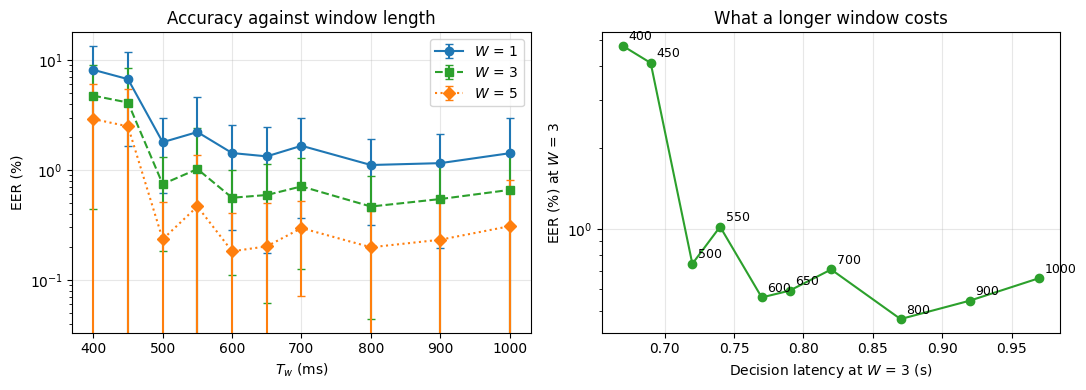


Written to results/window-sweep-rotated/


In [14]:
# Part 9: Does the sweep discriminate, and what does it choose?
# ---------------------------------------------------------------------------

per_fold = raw.groupby(['window_ms', 'fold', 'heldout'],
                       as_index=False).mean(numeric_only=True)
rows = []
for tw in SWEEP_WINDOWS:
    sub = per_fold[per_fold['window_ms'] == tw]
    if sub.empty:
        continue
    r = {'T_w(ms)': tw, 'n_folds': len(sub)}
    for w in SMOOTHING_WINDOWS:
        m, sd = mean_sd(sub[f'eer_W{w}'].dropna().values * 100)
        r[f'EER_W{w}(%)'] = round(m, 3)
        r[f'SD_W{w}'] = round(sd, 3)
    r['at_floor_W3'] = int((sub['eer_W3'] == 0).sum())
    r['at_floor_W5'] = int((sub['eer_W5'] == 0).sum())
    r['latency_W3(s)'] = round(latency(tw, 3), 2)
    r['latency_W5(s)'] = round(latency(tw, 5), 2)
    rows.append(r)
summary = pd.DataFrame(rows)
summary.to_csv(f'{OUTDIR}/sweep_summary.csv', index=False)
per_fold.to_csv(f'{OUTDIR}/sweep_per_fold.csv', index=False)

cols = ['T_w(ms)', 'EER_W1(%)', 'SD_W1', 'EER_W3(%)', 'SD_W3', 'EER_W5(%)',
        'SD_W5', 'at_floor_W3', 'at_floor_W5', 'latency_W3(s)', 'latency_W5(s)']
print("=== Feature-window sweep, rotated protocol, two-branch model ===")
print(summary[cols].to_string(index=False))

print("\n=== Does the protocol discriminate? ===")
for w in (1, 3, 5):
    v = summary[f'EER_W{w}(%)'].values
    lo = max(v.min(), 1e-9)
    print(f"  W = {w}: {v.min():.3f}% to {v.max():.3f}%   ratio {v.max()/lo:.1f}x   "
          f"{'usable' if v.max() > 2 * lo else 'NOT discriminating'}")

print(f"\n=== Paired against T_w = {REFERENCE_TW} ms (Wilcoxon, 9 folds) ===")
# Every window is compared with the same reference, so this is a family of
# nine tests and the p-values need adjusting. Without it, at alpha = 0.05 the
# chance of at least one spurious "significant" result across nine independent
# comparisons is about 37%. Holm is used: it controls the family-wise error rate
# and, unlike Bonferroni, loses little power.
def holm(pvals):
    order = np.argsort(pvals)
    n = len(pvals)
    adj = np.empty(n)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (n - rank) * pvals[idx])
        adj[idx] = min(1.0, running)
    return adj

for w in (3, 5):
    piv = per_fold.pivot_table(index='heldout', columns='window_ms',
                               values=f'eer_W{w}')
    if REFERENCE_TW not in piv.columns:
        continue
    base = piv[REFERENCE_TW].values * 100
    tws, means, wins, ps = [], [], [], []
    for tw in SWEEP_WINDOWS:
        if tw == REFERENCE_TW or tw not in piv.columns:
            continue
        a = piv[tw].values * 100
        if np.isnan(a).any() or np.isnan(base).any():
            continue
        stat, p = wilcoxon(a, base)
        tws.append(tw); means.append(float(np.mean(a)))
        wins.append(int((a < base).sum())); ps.append(float(p))
    if not tws:
        continue
    adj = holm(np.array(ps))
    print(f"  at W = {w}   (reference {np.mean(base):.3f}%)")
    for tw, m, win, p, pa in zip(tws, means, wins, ps, adj):
        verdict = ("better" if m < np.mean(base) and pa < 0.05 else
                   "worse" if m > np.mean(base) and pa < 0.05 else
                   "not separable")
        print(f"    {tw:5d} ms {m:7.3f}%   better in {win}/9   "
              f"p = {p:.4f}   Holm p = {pa:.4f}   {verdict}")

best = summary.loc[summary['EER_W3(%)'].idxmin()]
print(f"\n  lowest EER at W = 3: T_w = {int(best['T_w(ms)'])} ms "
      f"({best['EER_W3(%)']:.3f}%), latency {best['latency_W3(s)']:.2f} s")
print("  If the settings above 400 ms are not separable, the honest reading is")
print("  that the model is insensitive to T_w over that range and the choice")
print("  should be made on latency, which favours the shortest usable window.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for w, mk, col in ((1, 'o-', 'C0'), (3, 's--', 'C2'), (5, 'D:', 'C1')):
    axes[0].errorbar(summary['T_w(ms)'], np.maximum(summary[f'EER_W{w}(%)'], 1e-3),
                     yerr=summary[f'SD_W{w}'], fmt=mk, color=col, capsize=3,
                     label=f'$W$ = {w}')
axes[0].set_yscale('log'); axes[0].set_xlabel('$T_w$ (ms)')
axes[0].set_ylabel('EER (%)'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[0].set_title('Accuracy against window length')

axes[1].plot(summary['latency_W3(s)'], summary['EER_W3(%)'], 'o-', color='C2')
for _, r in summary.iterrows():
    axes[1].annotate(f"{int(r['T_w(ms)'])}", (r['latency_W3(s)'], r['EER_W3(%)']),
                     textcoords='offset points', xytext=(4, 4), fontsize=9)
axes[1].set_xlabel('Decision latency at $W$ = 3 (s)')
axes[1].set_ylabel('EER (%) at $W$ = 3')
axes[1].set_yscale('log'); axes[1].grid(alpha=.3)
axes[1].set_title('What a longer window costs')
plt.tight_layout()
plt.savefig(f'{OUTDIR}/window_sweep_rotated.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"\nWritten to {OUTDIR}/")

=== Feature-window sweep, rotated protocol, two-branch model ===
configuration: batch_size=64, dropout=0.128616, hidden_dim=32, lr=0.000389513, num_layers=1, target_len=35, weight_decay=1.18581e-05
 T_w(ms)  EER_W1(%)  SD_W1  EER_W3(%)  SD_W3  EER_W5(%)  SD_W5  at_floor_W3  at_floor_W5  latency_W3(s)  latency_W5(s)
     400      8.156  5.279      4.746  4.307      2.909  3.167            0            0           0.67           1.13
     450      6.708  5.048      4.108  4.327      2.494  2.992            0            0           0.69           1.16
     500      1.790  1.179      0.744  0.561      0.234  0.279            0            0           0.72           1.18
     550      2.214  2.392      1.020  1.407      0.466  0.903            0            1           0.74           1.21
     600      1.426  1.139      0.559  0.449      0.182  0.226            0            1           0.77           1.23
     650      1.330  1.156      0.592  0.530      0.202  0.294            1            1

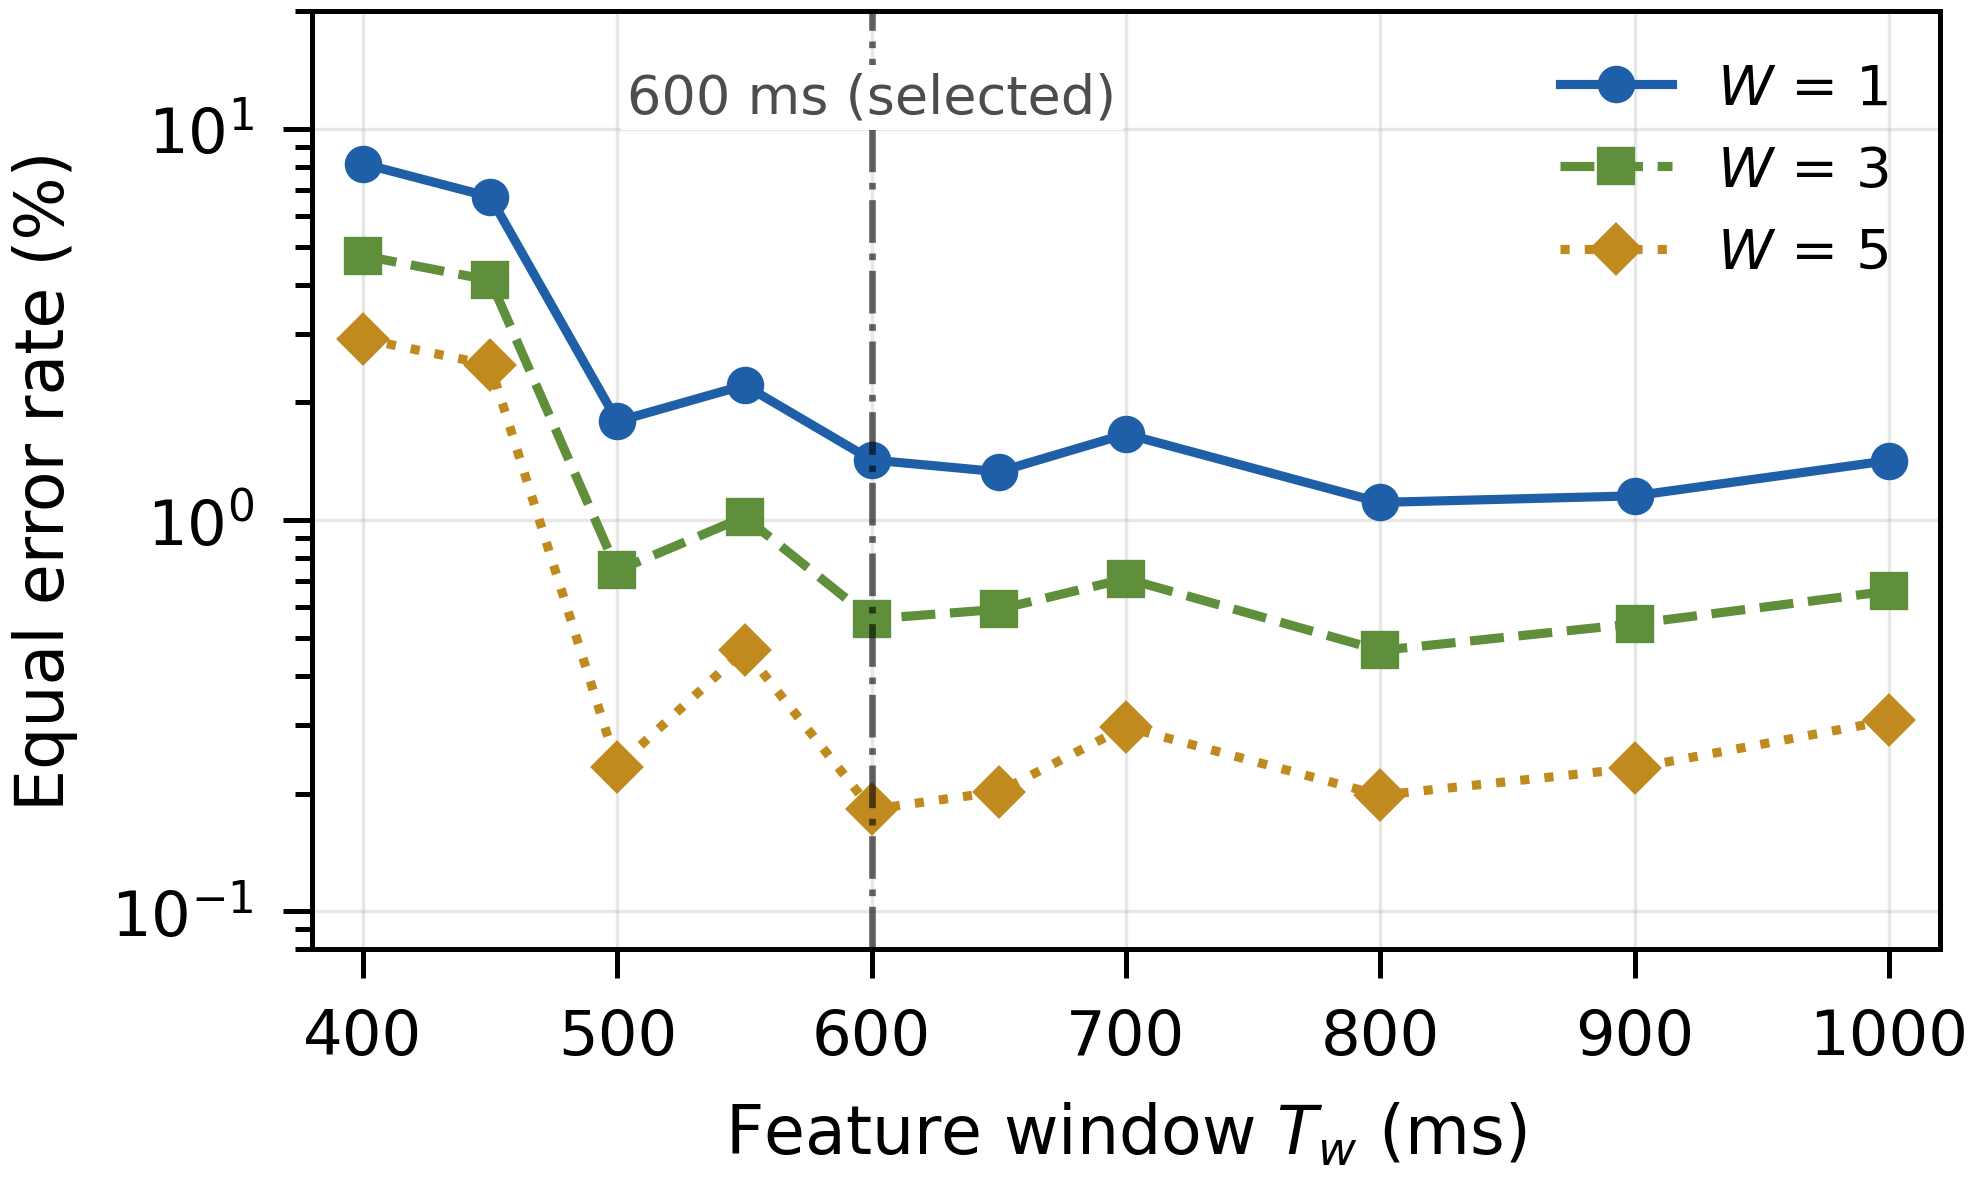


Written to results/window-sweep-rotated/


In [15]:
# Part 9: Does the sweep discriminate, and what does it choose?
# ---------------------------------------------------------------------------

per_fold = raw.groupby(['window_ms', 'fold', 'heldout'],
                       as_index=False).mean(numeric_only=True)
rows = []
for tw in SWEEP_WINDOWS:
    sub = per_fold[per_fold['window_ms'] == tw]
    if sub.empty:
        continue
    r = {'T_w(ms)': tw, 'n_folds': len(sub)}
    for w in SMOOTHING_WINDOWS:
        m, sd = mean_sd(sub[f'eer_W{w}'].dropna().values * 100)
        r[f'EER_W{w}(%)'] = round(m, 3)
        r[f'SD_W{w}'] = round(sd, 3)
    r['at_floor_W3'] = int((sub['eer_W3'] == 0).sum())
    r['at_floor_W5'] = int((sub['eer_W5'] == 0).sum())
    r['latency_W3(s)'] = round(latency(tw, 3), 2)
    r['latency_W5(s)'] = round(latency(tw, 5), 2)
    rows.append(r)
summary = pd.DataFrame(rows)
summary.to_csv(f'{OUTDIR}/sweep_summary.csv', index=False)
per_fold.to_csv(f'{OUTDIR}/sweep_per_fold.csv', index=False)

cols = ['T_w(ms)', 'EER_W1(%)', 'SD_W1', 'EER_W3(%)', 'SD_W3', 'EER_W5(%)',
        'SD_W5', 'at_floor_W3', 'at_floor_W5', 'latency_W3(s)', 'latency_W5(s)']
print("=== Feature-window sweep, rotated protocol, two-branch model ===")
print(f"configuration: " + ", ".join(
    f"{k}={v:.6g}" if isinstance(v, float) else f"{k}={v}"
    for k, v in sorted(PARAMS.items())))
print(summary[cols].to_string(index=False))

print("\n=== Does the protocol discriminate? ===")
for w in (1, 3, 5):
    v = summary[f'EER_W{w}(%)'].values
    lo = max(v.min(), 1e-9)
    print(f"  W = {w}: {v.min():.3f}% to {v.max():.3f}%   ratio {v.max()/lo:.1f}x   "
          f"{'usable' if v.max() > 2 * lo else 'NOT discriminating'}")

print(f"\n=== Paired against T_w = {REFERENCE_TW} ms (Wilcoxon, {len(FOLDS)} folds) ===")
# Every window is compared with the same reference, so this is a family of
# nine tests and the p-values need adjusting. Without it, at alpha = 0.05 the
# chance of at least one spurious "significant" result across nine independent
# comparisons is about 37%.
def holm(p):
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    n = len(p)
    adj = np.empty(n)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (n - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj

NOT_SEPARABLE = {}          # W -> list of T_w indistinguishable from the reference
for w in (1, 3, 5):
    piv = per_fold.pivot_table(index='heldout', columns='window_ms',
                               values=f'eer_W{w}')
    if REFERENCE_TW not in piv.columns:
        continue
    base = piv[REFERENCE_TW].values * 100
    tws, means, wins, ps = [], [], [], []
    for tw in SWEEP_WINDOWS:
        if tw == REFERENCE_TW or tw not in piv.columns:
            continue
        a = piv[tw].values * 100
        if np.isnan(a).any() or np.isnan(base).any():
            continue
        stat, p = wilcoxon(a, base)
        tws.append(tw); means.append(float(np.mean(a)))
        wins.append(int((a < base).sum())); ps.append(float(p))
    if not tws:
        continue
    adj = holm(np.array(ps))
    n_folds = len(base)
    print(f"  at W = {w}   (reference {np.mean(base):.3f}%)")
    flat = [REFERENCE_TW]
    for tw, m, win, p, pa in zip(tws, means, wins, ps, adj):
        verdict = ("better" if m < np.mean(base) and pa < 0.05 else
                   "worse" if m > np.mean(base) and pa < 0.05 else
                   "not separable")
        if verdict == "not separable":
            flat.append(tw)
        print(f"    {tw:5d} ms {m:7.3f}%   better in {win}/{n_folds}   "
              f"p = {p:.4f}   Holm p = {pa:.4f}   {verdict}")
    NOT_SEPARABLE[w] = sorted(flat)

best = summary.loc[summary['EER_W3(%)'].idxmin()]
print(f"\n  lowest EER at W = 3: T_w = {int(best['T_w(ms)'])} ms "
      f"({best['EER_W3(%)']:.3f}%), latency {best['latency_W3(s)']:.2f} s")
print("  If the settings above 400 ms are not separable, the honest reading is")
print("  that the model is insensitive to T_w over that range and the choice")
print("  should be made on latency, which favours the shortest usable window.")

# --- closing the loop with the hyperparameter search -------------------------
# Optuna-Nested-TwoBranch.ipynb held T_w at SEARCH_TW on the authority of the
# previous run of this sweep, and this sweep varies T_w using the configuration
# that search returned. That sequence is only sound if SEARCH_TW is still inside
# the range this sweep cannot separate from its reference. State the answer
# rather than leave it to be inferred from the table above.
SEARCH_TW = 600
print("\n=== Is the hyperparameter search still standing on this sweep? ===")
print(f"  the search fixed T_w = {SEARCH_TW} ms; this sweep, run with the "
      f"configuration it returned, finds:")
# The set is not necessarily an interval, so list it rather than print a range:
# "500-1000 ms" would misdescribe a set that skips 800.
_all_ok = bool(NOT_SEPARABLE)
for w in sorted(NOT_SEPARABLE):
    rng = NOT_SEPARABLE[w]
    inside = SEARCH_TW in rng
    _all_ok &= inside
    contiguous = rng == [t for t in SWEEP_WINDOWS if min(rng) <= t <= max(rng)]
    shown = (f"{min(rng)}-{max(rng)} ms" if contiguous and len(rng) > 1
             else ", ".join(f"{t}" for t in rng) + " ms")
    print(f"    W = {w}: not separable from the reference at {shown} "
          f"({len(rng)} of {len(SWEEP_WINDOWS)} settings); "
          f"{SEARCH_TW} ms is {'INSIDE' if inside else 'OUTSIDE'} it")
if not NOT_SEPARABLE:
    print("    no comparison could be made (the reference window is missing "
          "from the collected results), so this question is unanswered.")
elif _all_ok:
    print(f"\n  -> {SEARCH_TW} ms lies inside the flat basin at every operating "
          f"point. The two were settled in sequence, not jointly, and the text "
          f"should say so; but no re-run is required.")
else:
    print(f"\n  -> {SEARCH_TW} ms falls outside the basin at one or more "
          f"operating points. The hyperparameters were chosen at a window this "
          f"sweep now rejects, so the search must be repeated at the preferred "
          f"window before either result is reported.")

# --- figures -----------------------------------------------------------------
# The window-sweep figure is produced by figures/make_figures.py, which reads results/
# and nothing else. Drawing them again here would mean two definitions of the
# same figure in two styles, and the one shown in the notebook would not be the
# one in the paper. Run that script for this figure only, and display what
# it wrote, so what appears below is the file LaTeX includes.
#
# (function name in make_figures.py, file it writes)
FIGURES = [('fig_window_sweep', 'fig_window_sweep')]

import subprocess, sys as _sys
from IPython.display import Image, display

_script = 'figures/make_figures.py'
_r = subprocess.run([_sys.executable, os.path.abspath(_script)] + [f for f, _ in FIGURES],
                    capture_output=True, text=True)
print(_r.stdout.rstrip())
if _r.returncode != 0:
    print(_r.stderr.rstrip()[-2000:])
    raise RuntimeError(f"{_script} exited {_r.returncode}")

# make_figures.py chdir()s to the repository root; resolve its output the same
# way rather than assuming this notebook's cwd is that root.
_root = os.path.dirname(os.path.dirname(os.path.abspath(_script)))
for _, _name in FIGURES:
    _p = os.path.join(_root, 'figures', 'normal', f'{_name}.png')
    print(f"\n{os.path.relpath(_p, _root)}")
    display(Image(filename=_p))

with open(f'{OUTDIR}/run_params.json', 'w', encoding='utf-8') as _f:
    json.dump({**RUN_STAMP,
               'not_separable_from_reference': NOT_SEPARABLE,
               'search_tw_inside_basin': bool(_all_ok),
               'n_runs': int(len(raw)), 'n_skipped': int(len(skips))},
              _f, indent=2, default=str)
print(f"\nWritten to {OUTDIR}/")
